### 1. Planeamento e Configuração do Ambiente Analítico

#### 1.1. Importação das Bibliotecas e Leitura dos Dados

In [1]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

# Carregar o ficheiro .csv
file_path = 'br_me_siape_servidores_executivo_federal.csv'
df = pd.read_csv(file_path)

# Exibir as primeiras linhas do DataFrame para verificar o carregamento
display(df.head())
df.shape


,orgao_vinculacao,orgao_exercicio,sexo,raca_cor,situacao_vinculo,funcao,nivel_funcao,atividade,data_admissao
0,MINISTERIO DA EDUCACAO,UNIVERSIDADE FEDERAL DO RIO GRANDE,F,BRANCA,ATIVO PERMANENTE,NaN,NaN,NaN,2014-02-27
1,MINISTERIO DA EDUCACAO,UNIVERSIDADE FEDERAL DO RIO GRANDE,M,BRANCA,ATIVO PERMANENTE,CD,CD-4,DIRETOR,2004-07-05
2,MINISTERIO DA EDUCACAO,FUND.UNIV.FED.CIENC.SAUDE D PORTO ALEGRE,F,BRANCA,RESIDENCIA E PMM,NaN,NaN,NaN,2021-03-01
3,MINISTERIO DA EDUCACAO,UNIVERSIDADE FEDERAL DO RIO GRANDE,F,BRANCA,ATIVO PERMANENTE,NaN,NaN,NaN,2006-08-24
4,MINISTERIO DA EDUCACAO,UNIVERSIDADE FEDERAL DO RIO GRANDE,F,BRANCA,ATIVO PERMANENTE,NaN,NaN,NaN,2006-08-02


(358869, 9)

#### 1.1.1. Constantes Globais e Função Utilitária de Rotulagem

Limites temporais e mapeamento hierárquico usados em todo o notebook, definidos uma única vez para evitar o tipo de inconsistência encontrada na Seção 4 (ver `Analise_Notebook_SIAPE_e_Base_de_Dados.md`).

In [2]:
# Limites temporais dos períodos de análise (fonte única - usados em todo o notebook)
ANO_INICIO_PRE_COTAS = 1990
ANO_FIM_PRE_COTAS = 2014
ANO_INICIO_POS_COTAS = 2015
ANO_FIM_POS_COTAS = 2022

# Mapeamento do proxy hierárquico (NÃO é remuneração real - ver Seção 7.1)
MAPEAMENTO_HIERARQUICO_PROXY = {
    'Outros Cargos': 0,
    'Gerência/Coordenação': 1,
    'Alta Gestão/Direção': 2,
}

# --- Padronização visual dos gráficos (tema, cores, fontes, tamanhos) ---

# Paleta categórica fixa, em ordem validada para segurança a daltonismo
# (ΔE >= 8 entre pares adjacentes; ver dataviz skill, references/palette.md).
PALETA_CATEGORICA = [
    '#2a78d6',  # azul
    '#eb6834',  # laranja
    '#1baf7a',  # verde-água
    '#eda100',  # amarelo
    '#e87ba4',  # magenta
    '#008300',  # verde
    '#4a3aa7',  # violeta
    '#e34948',  # vermelho
]

# BRANCA/NEGROS é o par que se repete na maioria dos gráficos do notebook -
# mantém a mesma cor em todos eles para preservar a identidade visual.
COR_BRANCA = PALETA_CATEGORICA[0]
COR_NEGROS = PALETA_CATEGORICA[1]
PALETA_RACA = {'BRANCA': COR_BRANCA, 'NEGROS': COR_NEGROS}

# Fonte e hierarquia de tamanhos únicas para todos os gráficos (mesma fonte
# do artigo - Times New Roman - com fallback para quem não a tiver instalada).
plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'Liberation Serif', 'DejaVu Serif'],
    'font.size': 11,
    'axes.titlesize': 14,
    'axes.titleweight': 'bold',
    'axes.labelsize': 11,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'legend.title_fontsize': 10,
    'figure.dpi': 120,
    'axes.ymargin': 0.12,  # respiro extra acima da maior barra, evita rótulo colidir com o título
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': False,
    'grid.color': '#c3c2b7',
    'grid.linestyle': '--',
    'grid.alpha': 0.4,
})
sns.set_theme(style='white')

# Tamanhos de figura padronizados: SIMPLES para 2-3 categorias em série
# única, AMPLO para gráficos agrupados (hue), com muitas categorias no
# eixo x, ou com legenda.
FIGSIZE_SIMPLES = (9, 6)
FIGSIZE_AMPLO = (13, 7)


### 1.2. Análise Exploratória Inicial (Estrutura de Dados)

In [3]:
# Converter 'data_admissao' para o tipo datetime
df['data_admissao'] = pd.to_datetime(df['data_admissao'], errors='coerce')

# Verificar as informações do DataFrame novamente após a conversão
print("\nInformações do DataFrame após conversão de 'data_admissao':")
df.info()


Informações do DataFrame após conversão de 'data_admissao':
<class 'pandas.DataFrame'>
RangeIndex: 358869 entries, 0 to 358868
Data columns (total 9 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   orgao_vinculacao  358869 non-null  str           
 1   orgao_exercicio   358869 non-null  str           
 2   sexo              358869 non-null  str           
 3   raca_cor          358685 non-null  str           
 4   situacao_vinculo  358869 non-null  str           
 5   funcao            82060 non-null   str           
 6   nivel_funcao      82060 non-null   str           
 7   atividade         82060 non-null   str           
 8   data_admissao     358869 non-null  datetime64[us]
dtypes: datetime64[us](1), str(8)
memory usage: 24.6 MB


In [4]:
print("\nAnálise das Variáveis:\n")
for col in df.columns:
    print(f"--- Coluna: {col} ---")
    print(f"Tipo de dado: {df[col].dtype}")
    print(f"Valores únicos: {df[col].nunique()}")
    print(f"Top 5 valores: {df[col].value_counts().head(5).to_dict()}")
    missing_count = df[col].isnull().sum()
    missing_percentage = (missing_count / len(df)) * 100
    print(f"Valores ausentes: {missing_count} ({missing_percentage:.2f}%)")
    print("\n")


Análise das Variáveis:

--- Coluna: orgao_vinculacao ---
Tipo de dado: str
Valores únicos: 20
Top 5 valores: {'MINISTERIO DA EDUCACAO': 215639, 'MINISTERIO DA ECONOMIA': 46338, 'MINISTERIO DA SAUDE': 25109, 'MINIST. DA JUSTICA E SEGURANCA PUBLICA': 14592, 'PRESIDENCIA DA REPUBLICA': 11972}
Valores ausentes: 0 (0.00%)


--- Coluna: orgao_exercicio ---
Tipo de dado: str
Valores únicos: 188
Top 5 valores: {'MINISTERIO DA ECONOMIA': 22369, 'MINISTERIO DA SAUDE': 19089, 'INSTITUTO NACIONAL DE SEGURO SOCIAL': 10876, 'DEPARTAMENTO DE POLICIA FEDERAL': 7151, 'ADVOCACIA-GERAL DA UNIAO': 6383}
Valores ausentes: 0 (0.00%)


--- Coluna: sexo ---
Tipo de dado: str
Valores únicos: 2
Top 5 valores: {'M': 197186, 'F': 161683}
Valores ausentes: 0 (0.00%)


--- Coluna: raca_cor ---
Tipo de dado: str
Valores únicos: 6
Top 5 valores: {'BRANCA': 195573, 'PARDA': 107583, 'PRETA': 25539, 'NÃO INFORMADO': 18849, 'AMARELA': 9864}
Valores ausentes: 184 (0.05%)


--- Coluna: situacao_vinculo ---
Tipo de dado: s

Top 5 valores: {'ATIVO PERMANENTE': 302066, 'CONT.PROF.SUBSTITUTO': 8544, 'ATIVO EM OUTRO ORGAO': 8534, 'CEDIDO/REQUISITADO': 7122, 'CEDIDO SUS/LEI 8270': 6839}
Valores ausentes: 0 (0.00%)


--- Coluna: funcao ---
Tipo de dado: str
Valores únicos: 21
Top 5 valores: {'FG': 21499, 'FUC': 10681, 'CD': 8426, 'FPE': 8401, 'FGR': 7850}
Valores ausentes: 276809 (77.13%)


--- Coluna: nivel_funcao ---
Tipo de dado: str
Valores únicos: 207


Top 5 valores: {'FG-1': 10746, 'FUC-1': 10681, 'FG-2': 7453, 'CD-4': 4846, 'FGR-1': 3099}
Valores ausentes: 276809 (77.13%)


--- Coluna: atividade ---
Tipo de dado: str
Valores únicos: 268
Top 5 valores: {'COORDENADOR': 16919, 'COORDENADOR DE CURSO': 5389, 'CHEFE': 5043, 'DIRETOR': 3850, 'CHEFE DE DIVISAO': 3495}
Valores ausentes: 276809 (77.13%)


--- Coluna: data_admissao ---
Tipo de dado: datetime64[us]
Valores únicos: 14314
Top 5 valores: {Timestamp('2021-03-01 00:00:00'): 452, Timestamp('2022-03-01 00:00:00'): 368, Timestamp('1995-01-02 00:00:00'): 356, Timestamp('2010-02-01 00:00:00'): 354, Timestamp('1988-10-04 00:00:00'): 319}
Valores ausentes: 0 (0.00%)




### 2. Limpeza e Pré-processamento dos Dados (Data Cleaning)

#### 2.1. Tratamento da Variável Temporal

In [5]:
# Extrair o ano de ingresso de cada servidor
df['ano_admissao'] = df['data_admissao'].dt.year

# Exibir as primeiras linhas com a nova coluna 'ano_admissao'
display(df.head())

,orgao_vinculacao,orgao_exercicio,sexo,raca_cor,situacao_vinculo,funcao,nivel_funcao,atividade,data_admissao,ano_admissao
0,MINISTERIO DA EDUCACAO,UNIVERSIDADE FEDERAL DO RIO GRANDE,F,BRANCA,ATIVO PERMANENTE,NaN,NaN,NaN,2014-02-27,2014
1,MINISTERIO DA EDUCACAO,UNIVERSIDADE FEDERAL DO RIO GRANDE,M,BRANCA,ATIVO PERMANENTE,CD,CD-4,DIRETOR,2004-07-05,2004
2,MINISTERIO DA EDUCACAO,FUND.UNIV.FED.CIENC.SAUDE D PORTO ALEGRE,F,BRANCA,RESIDENCIA E PMM,NaN,NaN,NaN,2021-03-01,2021
3,MINISTERIO DA EDUCACAO,UNIVERSIDADE FEDERAL DO RIO GRANDE,F,BRANCA,ATIVO PERMANENTE,NaN,NaN,NaN,2006-08-24,2006
4,MINISTERIO DA EDUCACAO,UNIVERSIDADE FEDERAL DO RIO GRANDE,F,BRANCA,ATIVO PERMANENTE,NaN,NaN,NaN,2006-08-02,2006


#### 2.2. Tratamento de Valores Ausentes

In [6]:
# Preencher valores ausentes em colunas específicas com 'Nao Informado'
columns_to_fill_all = ['funcao', 'nivel_funcao', 'atividade', 'raca_cor']
for col in columns_to_fill_all:
    df[col] = df[col].fillna('Nao Informado')

# Verificar novamente a contagem de valores ausentes para confirmar
print("Valores ausentes após o tratamento:")
print(df[columns_to_fill_all].isnull().sum())

Valores ausentes após o tratamento:
funcao          0
nivel_funcao    0
atividade       0
raca_cor        0
dtype: int64


#### 2.2.1. Remoção de Registos com 'raca_cor' como 'Não informado'

In [7]:
# Contagem de 'Não informado' e 'Nao Informado' em 'raca_cor' antes da remoção
count_nao_informado_accent = df['raca_cor'].value_counts().get('NÃO INFORMADO', 0)
count_nao_informado_no_accent = df['raca_cor'].value_counts().get('Nao Informado', 0)
print(f"Contagem de 'NÃO INFORMADO' (com acento) em 'raca_cor' antes da remoção: {count_nao_informado_accent}")
print(f"Contagem de 'Nao Informado' (sem acento) em 'raca_cor' antes da remoção: {count_nao_informado_no_accent}")

# Remover os registos onde 'raca_cor' é 'Nao Informado' ou 'NÃO INFORMADO'
df_filtered = df[~df['raca_cor'].isin(['Nao Informado', 'NÃO INFORMADO'])]

# Verificar a nova forma do DataFrame
print(f"\nShape do DataFrame após a remoção: {df_filtered.shape}")

# Criar tabela com contagem e percentual
tab_raca_cor = df_filtered['raca_cor'].value_counts().to_frame(name='Quantidade')
tab_raca_cor['Percentual (%)'] = (tab_raca_cor['Quantidade'] / tab_raca_cor['Quantidade'].sum() * 100).round(2)

# Exibir resultado
print("\nContagem e Percentual de valores em 'raca_cor' após a remoção:")
display(tab_raca_cor)

Contagem de 'NÃO INFORMADO' (com acento) em 'raca_cor' antes da remoção: 18849
Contagem de 'Nao Informado' (sem acento) em 'raca_cor' antes da remoção: 184



Shape do DataFrame após a remoção: (339836, 10)

Contagem e Percentual de valores em 'raca_cor' após a remoção:


,Quantidade,Percentual (%)
raca_cor,,
BRANCA,195573,57.55
PARDA,107583,31.66
PRETA,25539,7.52
AMARELA,9864,2.90
INDIGENA,1277,0.38


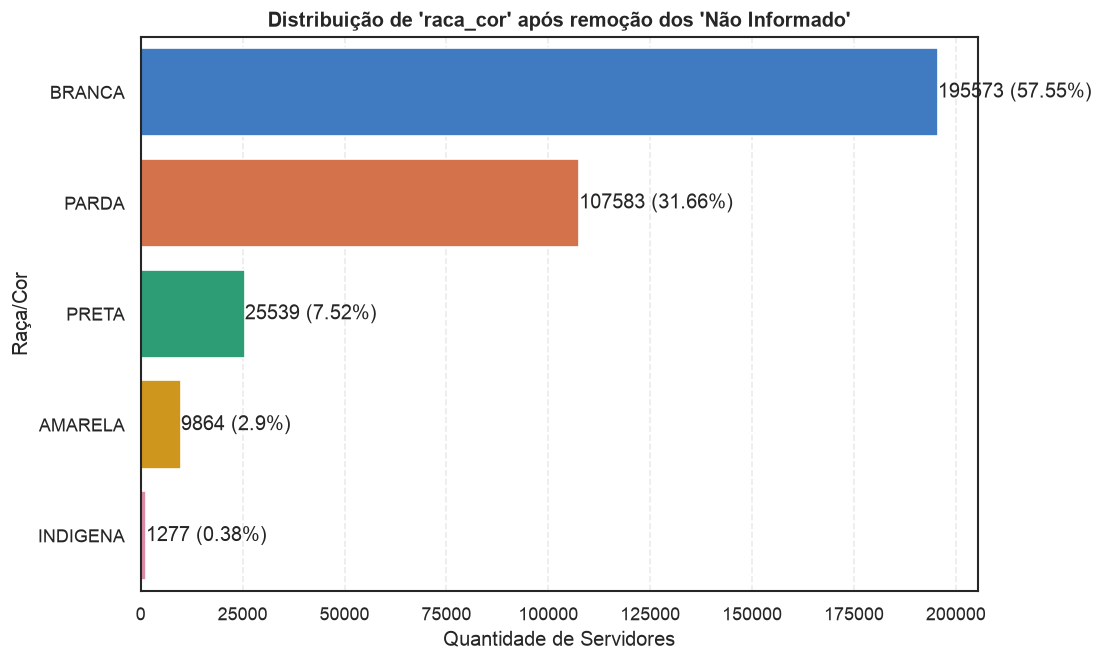

In [8]:
# Reaproveita a tabela já calculada na célula anterior (tab_raca_cor)
plt.figure(figsize=FIGSIZE_SIMPLES)
sns.barplot(
    x='Quantidade',
    y=tab_raca_cor.index,
    data=tab_raca_cor,
    palette=PALETA_CATEGORICA[:len(tab_raca_cor)],
    hue=tab_raca_cor.index,
    legend=False,
)

for i, (qtd, perc) in enumerate(zip(tab_raca_cor['Quantidade'], tab_raca_cor['Percentual (%)'])):
    plt.text(qtd + 5, i, f'{qtd} ({perc}%)', va='center')

plt.title("Distribuição de 'raca_cor' após remoção dos 'Não Informado'")
plt.xlabel("Quantidade de Servidores")
plt.ylabel("Raça/Cor")
plt.grid(axis='x', linestyle='--', alpha=0.4)
plt.show()


#### 2.2.2. Remoção Adicional de Registos: 'AMARELA' e 'INDIGENA' em 'raca_cor'

In [9]:
# Antes da remoção, verificar a contagem de 'AMARELA' e 'INDIGENA'
print("Contagem de 'AMARELA' em 'raca_cor' antes da remoção:" \
      f" {df_filtered['raca_cor'].value_counts().get('AMARELA', 0)}")
print("Contagem de 'INDIGENA' em 'raca_cor' antes da remoção:" \
      f" {df_filtered['raca_cor'].value_counts().get('INDIGENA', 0)}")

# Remover os registos onde 'raca_cor' é 'AMARELA' ou 'INDIGENA'
df_cleaned = df_filtered[~df_filtered['raca_cor'].isin(['AMARELA', 'INDIGENA'])].copy()

# Verificar a nova forma do DataFrame
print(f"\nShape do DataFrame após a remoção: {df_cleaned.shape}")

# Verificar a contagem de valores em 'raca_cor' após a remoção
print("\nContagem de valores em 'raca_cor' após a remoção:")
display(df_cleaned['raca_cor'].value_counts())

Contagem de 'AMARELA' em 'raca_cor' antes da remoção: 9864


Contagem de 'INDIGENA' em 'raca_cor' antes da remoção: 1277



Shape do DataFrame após a remoção: (328695, 10)

Contagem de valores em 'raca_cor' após a remoção:


raca_cor
BRANCA    195573
PARDA     107583
PRETA      25539
Name: count, dtype: int64

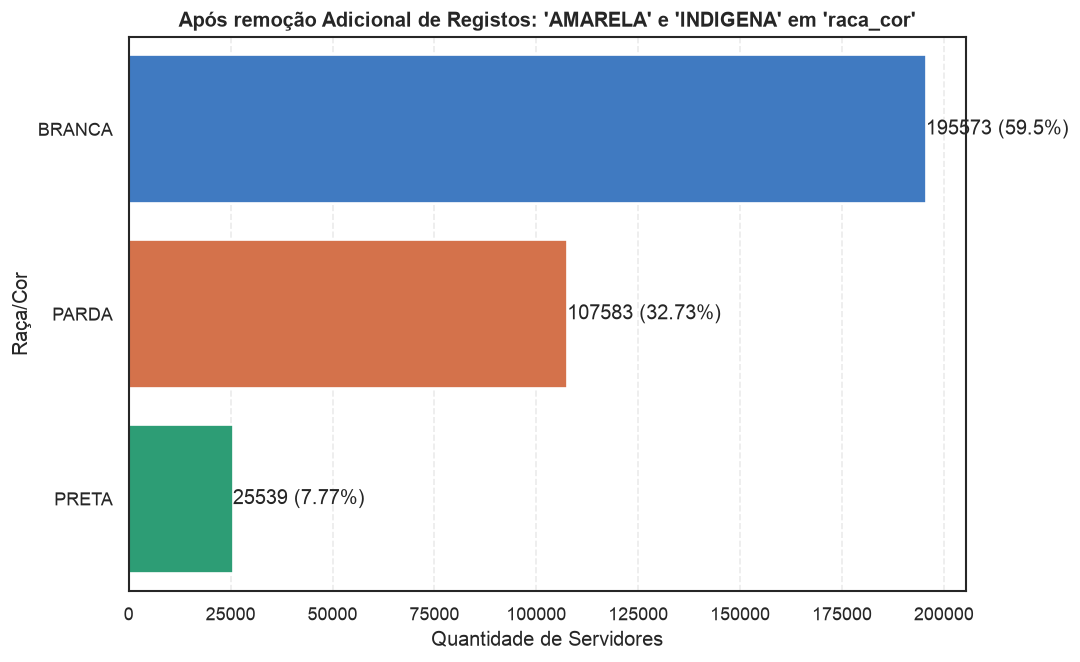

In [10]:
# Calcular contagens e percentuais
tab_raca_cor_cleaned = df_cleaned['raca_cor'].value_counts().to_frame(name='Quantidade')
tab_raca_cor_cleaned['Percentual (%)'] = (tab_raca_cor_cleaned['Quantidade'] / tab_raca_cor_cleaned['Quantidade'].sum() * 100).round(2)

# Plotar o gráfico de barras
plt.figure(figsize=FIGSIZE_SIMPLES)
sns.barplot(
    x='Quantidade',
    y=tab_raca_cor_cleaned.index,
    data=tab_raca_cor_cleaned,
    palette=PALETA_CATEGORICA[:len(tab_raca_cor_cleaned)],
    hue=tab_raca_cor_cleaned.index,
    legend=False,
)

# Adicionar valores absolutos e percentuais às barras
for i, (qtd, perc) in enumerate(zip(tab_raca_cor_cleaned['Quantidade'], tab_raca_cor_cleaned['Percentual (%)'])):
    plt.text(qtd + 5, i, f'{qtd} ({perc}%)', va='center')

plt.title("Após remoção Adicional de Registos: 'AMARELA' e 'INDIGENA' em 'raca_cor'")
plt.xlabel("Quantidade de Servidores")
plt.ylabel("Raça/Cor")
plt.grid(axis='x', linestyle='--', alpha=0.4)
plt.show()

## 2.3. Distribuição de Servidores por Órgão de Vinculação


In [11]:
tabulacao_orgao = df_cleaned['orgao_vinculacao'].value_counts().sort_values(ascending=False)

# Criar DataFrame com contagem e percentual
tabulacao_orgao_df = pd.DataFrame({
    'Quantidade': tabulacao_orgao,
    'Percentual (%)': (tabulacao_orgao / tabulacao_orgao.sum() * 100).round(2)
})

print("Quantidade de servidores por Órgão de Vinculação (ordenado decrescentemente):\n")
display(tabulacao_orgao_df)


Quantidade de servidores por Órgão de Vinculação (ordenado decrescentemente):



,Quantidade,Percentual (%)
orgao_vinculacao,,
MINISTERIO DA EDUCACAO,199649,60.74
MINISTERIO DA ECONOMIA,41702,12.69
MINISTERIO DA SAUDE,21461,6.53
MINIST. DA JUSTICA E SEGURANCA PUBLICA,12975,3.95
PRESIDENCIA DA REPUBLICA,11238,3.42
"MINIST.DA AGRICULTURA,PECUARIA E ABAST.",7423,2.26
MINISTERIO DA DEFESA,7390,2.25
MINISTERIO DA INFRAESTRUTURA,5061,1.54
MINISTERIO CIENCIA TEC.INOV.COMUNICACOES,4702,1.43


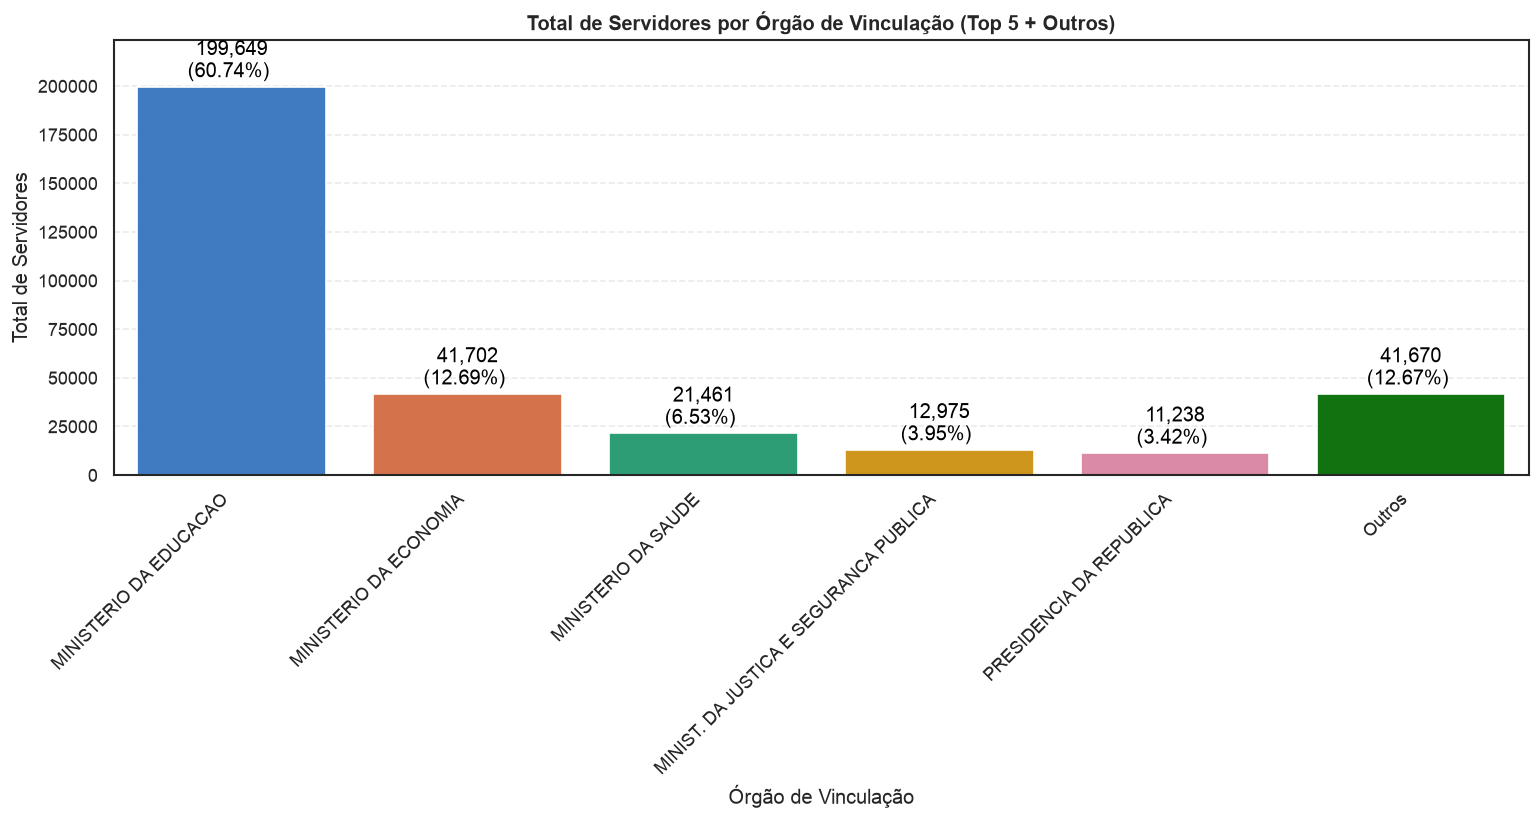

In [12]:
# Obter os top 5 órgãos
top_5_orgaos = tabulacao_orgao_df.head(5)

# Calcular a soma dos 'outros' órgãos
outros_quantidade = tabulacao_orgao_df['Quantidade'].iloc[5:].sum()
outros_percentual = tabulacao_orgao_df['Percentual (%)'].iloc[5:].sum().round(2)

# Criar uma nova linha para 'Outros'
outros_df = pd.DataFrame([{'Quantidade': outros_quantidade, 'Percentual (%)': outros_percentual}], index=['Outros'])

# Combinar os top 5 com 'Outros'
df_plot_orgao_top5 = pd.concat([top_5_orgaos, outros_df])

# Resetar o índice para usar no plot
df_plot_orgao_top5 = df_plot_orgao_top5.reset_index().rename(columns={'index': 'Orgao_Vinculacao'})

# Plotar o gráfico de barras
plt.figure(figsize=FIGSIZE_AMPLO)
sns.barplot(x='Orgao_Vinculacao', y='Quantidade', data=df_plot_orgao_top5, palette=PALETA_CATEGORICA[:len(df_plot_orgao_top5)], hue='Orgao_Vinculacao', dodge=False)

# Adicionar os valores absolutos e percentuais nas barras
for index, row in df_plot_orgao_top5.iterrows():
    plt.text(index, row['Quantidade'] + df_plot_orgao_top5['Quantidade'].max() * 0.01, # Ajuste de posição para não sobrepor
             f"{int(row['Quantidade']):,}\n({row['Percentual (%)']:.2f}%) ",
             color='black', ha="center", va='bottom')

plt.title('Total de Servidores por Órgão de Vinculação (Top 5 + Outros)')
plt.xlabel('Órgão de Vinculação')
plt.ylabel('Total de Servidores')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

### 3.1. Recodificação Étnico-Racial

Vamos recodificar a variável `raca_cor` para criar uma nova categoria denominada "Negros", agrupando os indivíduos autodeclarados como "Pretos" e "Pardos", e manter o grupo "Branca".

In [13]:
# Recodificação
df_cleaned['raca_cor_agrupada'] = df_cleaned['raca_cor'].replace({'PRETA': 'NEGROS', 'PARDA': 'NEGROS'})

# Criar tabela com contagem e percentual
tab_raca_cor_agrupada = df_cleaned['raca_cor_agrupada'].value_counts().to_frame(name='Quantidade')
tab_raca_cor_agrupada['Percentual (%)'] = (tab_raca_cor_agrupada['Quantidade'] / tab_raca_cor_agrupada['Quantidade'].sum() * 100).round(2)

# Exibir resultado
print("Contagem e Percentual de valores em 'raca_cor_agrupada' após a recodificação:")
display(tab_raca_cor_agrupada)


Contagem e Percentual de valores em 'raca_cor_agrupada' após a recodificação:


,Quantidade,Percentual (%)
raca_cor_agrupada,,
BRANCA,195573,59.5
NEGROS,133122,40.5


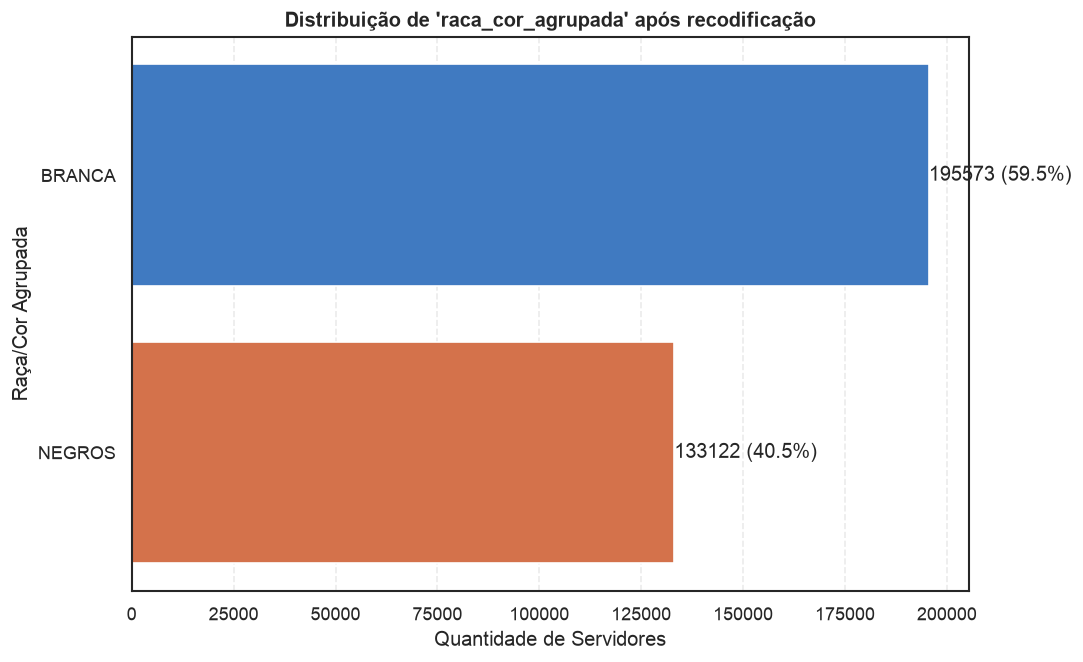

In [14]:
# Reaproveita a tabela já calculada na célula anterior (tab_raca_cor_agrupada)
plt.figure(figsize=FIGSIZE_SIMPLES)
sns.barplot(
    x='Quantidade',
    y=tab_raca_cor_agrupada.index,
    data=tab_raca_cor_agrupada,
    palette=PALETA_RACA,
    hue=tab_raca_cor_agrupada.index,
    legend=False,
)

for i, (qtd, perc) in enumerate(zip(tab_raca_cor_agrupada['Quantidade'], tab_raca_cor_agrupada['Percentual (%)'])):
    plt.text(qtd + 5, i, f'{qtd} ({perc}%)', va='center')

plt.title("Distribuição de 'raca_cor_agrupada' após recodificação")
plt.xlabel("Quantidade de Servidores")
plt.ylabel("Raça/Cor Agrupada")
plt.grid(axis='x', linestyle='--', alpha=0.4)
plt.show()


In [15]:
# Filtrar df_cleaned para incluir apenas 'NEGROS'
df_negros = df_cleaned[df_cleaned['raca_cor_agrupada'] == 'NEGROS'].copy()

# Tabulação de 'orgao_vinculacao' para 'NEGROS'
tabulacao_orgao_negros = df_negros['orgao_vinculacao'].value_counts().sort_values(ascending=False)

tabulacao_orgao_negros_df = pd.DataFrame({
    'Quantidade': tabulacao_orgao_negros,
    'Percentual (%)': (tabulacao_orgao_negros / tabulacao_orgao_negros.sum() * 100).round(2)
})

print("Quantidade de servidores NEGROS por Órgão de Vinculação (ordenado decrescentemente):\n")
display(tabulacao_orgao_negros_df)

Quantidade de servidores NEGROS por Órgão de Vinculação (ordenado decrescentemente):



,Quantidade,Percentual (%)
orgao_vinculacao,,
MINISTERIO DA EDUCACAO,78034,58.62
MINISTERIO DA ECONOMIA,17749,13.33
MINISTERIO DA SAUDE,10335,7.76
MINIST. DA JUSTICA E SEGURANCA PUBLICA,5650,4.24
PRESIDENCIA DA REPUBLICA,4436,3.33
MINISTERIO DA DEFESA,3405,2.56
"MINIST.DA AGRICULTURA,PECUARIA E ABAST.",3299,2.48
MINISTERIO DA INFRAESTRUTURA,2071,1.56
MINISTERIO DO MEIO AMBIENTE,1618,1.22


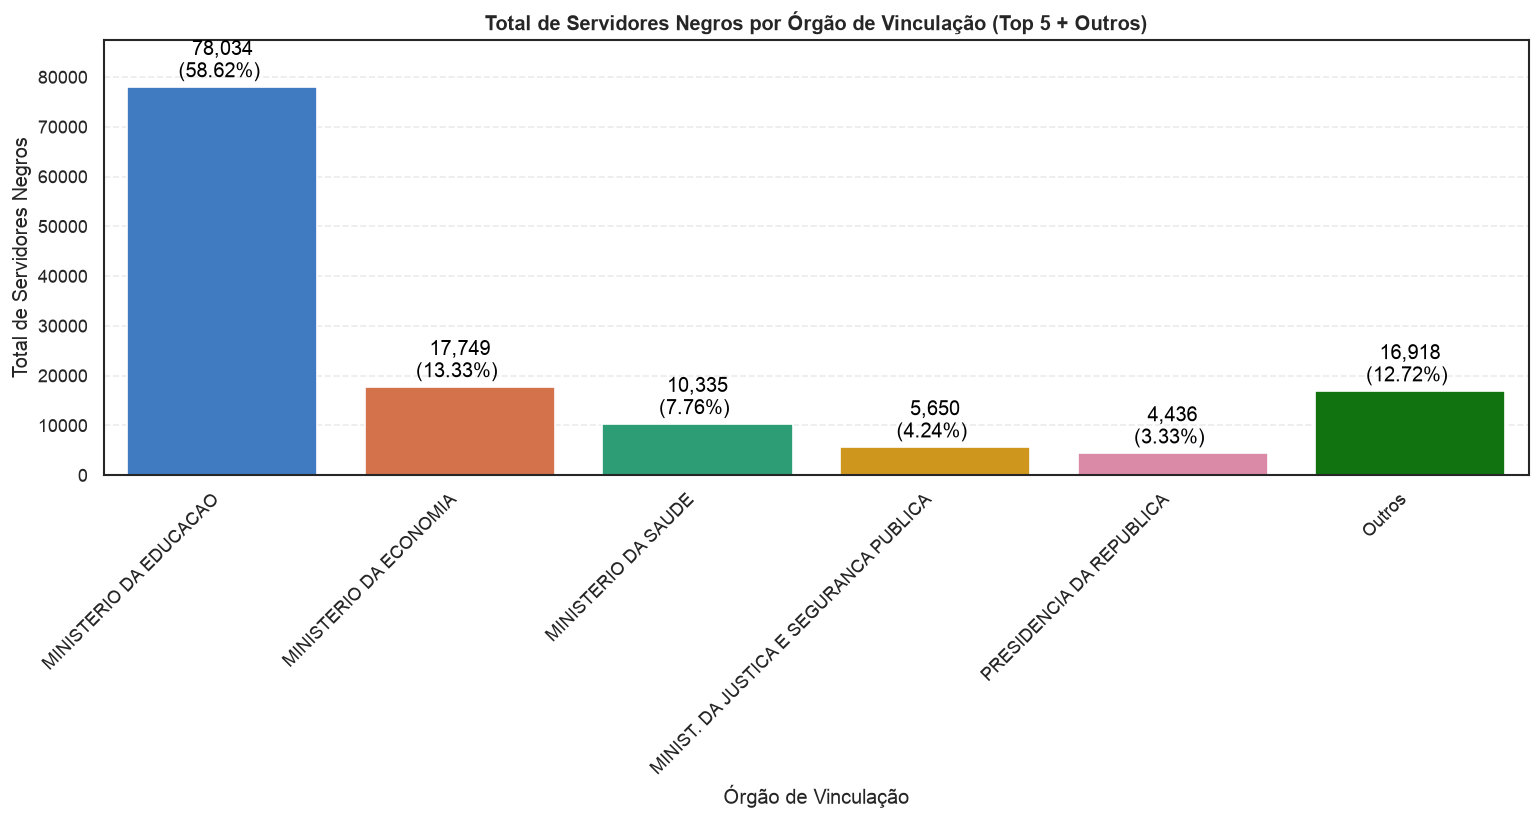

In [16]:
# Obter os top 5 órgãos para servidores NEGROS
top_5_orgaos_negros = tabulacao_orgao_negros_df.head(5)

# Calcular a soma dos 'outros' órgãos para servidores NEGROS
outros_quantidade_negros = tabulacao_orgao_negros_df['Quantidade'].iloc[5:].sum()
outros_percentual_negros = tabulacao_orgao_negros_df['Percentual (%)'].iloc[5:].sum().round(2)

# Criar uma nova linha para 'Outros' para servidores NEGROS
outros_df_negros = pd.DataFrame([{'Quantidade': outros_quantidade_negros, 'Percentual (%)': outros_percentual_negros}], index=['Outros'])

# Combinar os top 5 com 'Outros' para servidores NEGROS
df_plot_negros = pd.concat([top_5_orgaos_negros, outros_df_negros])

# Resetar o índice para usar no plot
df_plot_negros = df_plot_negros.reset_index().rename(columns={'index': 'Orgao_Vinculacao'})

# Plotar o gráfico de barras para servidores NEGROS
plt.figure(figsize=FIGSIZE_AMPLO)
sns.barplot(x='Orgao_Vinculacao', y='Quantidade', data=df_plot_negros, palette=PALETA_CATEGORICA[:len(df_plot_negros)], hue='Orgao_Vinculacao', dodge=False)

# Adicionar os valores absolutos e percentuais nas barras
for index, row in df_plot_negros.iterrows():
    plt.text(index, row['Quantidade'] + df_plot_negros['Quantidade'].max() * 0.01, # Ajuste de posição para não sobrepor
             f"{int(row['Quantidade']):,}\n({row['Percentual (%)']:.2f}%) ",
             color='black', ha="center", va='bottom')

plt.title('Total de Servidores Negros por Órgão de Vinculação (Top 5 + Outros)')
plt.xlabel('Órgão de Vinculação')
plt.ylabel('Total de Servidores Negros')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

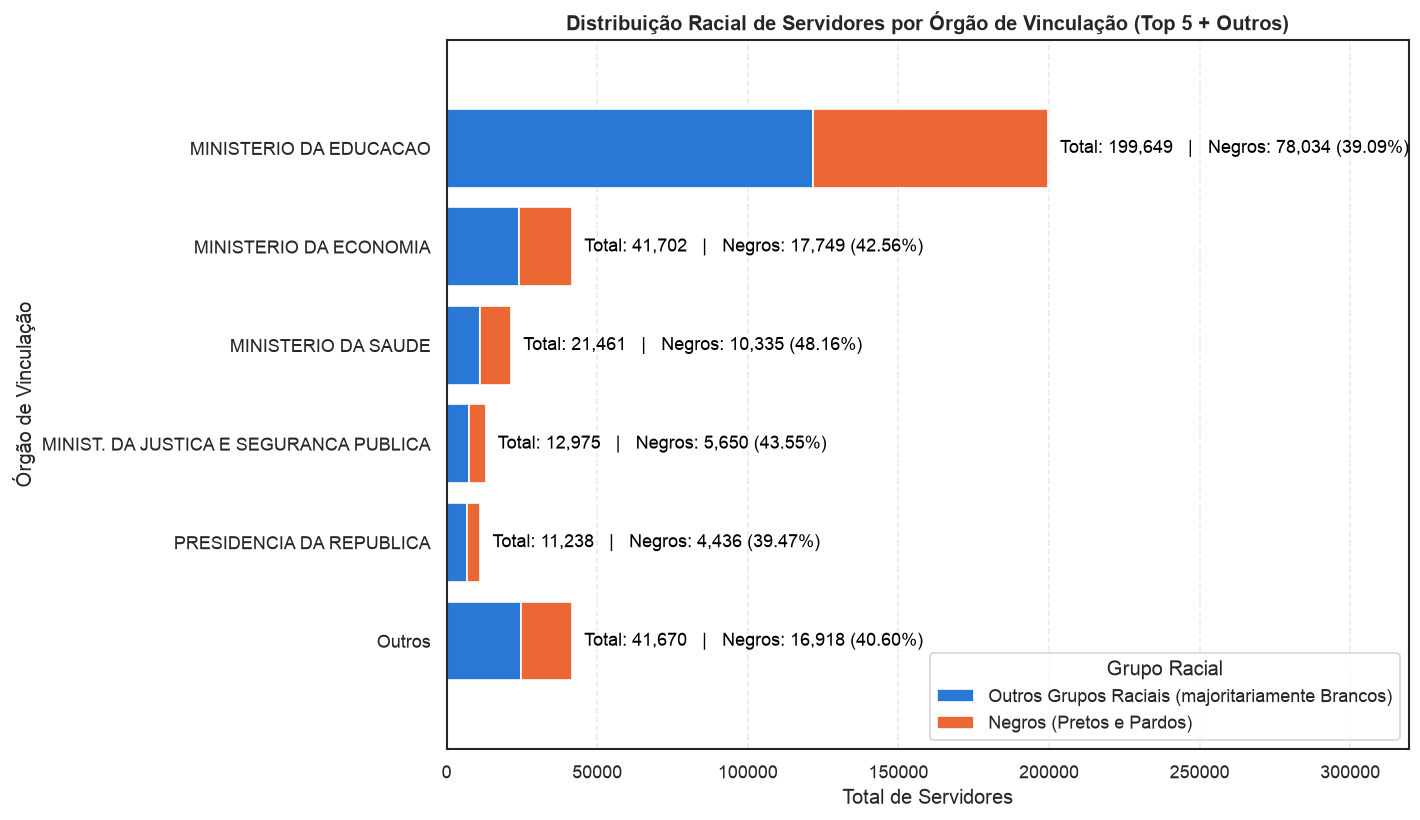

In [17]:
# Total de servidores por órgão, a partir de df_cleaned
total_servers_per_orgao = df_cleaned['orgao_vinculacao'].value_counts().sort_values(ascending=False)
total_servers_per_orgao_df = pd.DataFrame({
    'Total': total_servers_per_orgao
})

# Total de servidores negros por órgão, a partir de df_cleaned
negros_servers_per_orgao = df_cleaned[df_cleaned['raca_cor_agrupada'] == 'NEGROS']['orgao_vinculacao'].value_counts().sort_values(ascending=False)
negros_servers_per_orgao_df = pd.DataFrame({
    'Negros': negros_servers_per_orgao
})

# Combina os dois dataframes para obter as contagens totais e de negros por órgão
combined_orgao_data = pd.merge(total_servers_per_orgao_df, negros_servers_per_orgao_df, left_index=True, right_index=True, how='left')
combined_orgao_data['Negros'] = combined_orgao_data['Negros'].fillna(0).astype(int) # Fill NaN with 0 for agencies with no negros
combined_orgao_data['Outros'] = combined_orgao_data['Total'] - combined_orgao_data['Negros']

# Agrega em Top 5 + 'Outros' para o gráfico, com base no total de servidores
top_5_agencies_names = combined_orgao_data.head(5).index.tolist()

# Dados dos top 5 órgãos
df_plot_combined_top5 = combined_orgao_data.loc[top_5_agencies_names].reset_index().rename(columns={'orgao_vinculacao': 'Orgao_Vinculacao'})

# Dados da categoria 'Outros' (órgãos restantes)
outros_orgaos_data = combined_orgao_data.iloc[5:]
outros_total = outros_orgaos_data['Total'].sum()
outros_negros = outros_orgaos_data['Negros'].sum()
outros_outros = outros_orgaos_data['Outros'].sum()

outros_row = pd.DataFrame([
    {
        'Orgao_Vinculacao': 'Outros',
        'Total': outros_total,
        'Negros': outros_negros,
        'Outros': outros_outros
    }
])

df_plot_final_orgao_racial = pd.concat([df_plot_combined_top5, outros_row], ignore_index=True)

# Calcular percentuais para exibir nos rótulos
df_plot_final_orgao_racial['Perc_Negros'] = (df_plot_final_orgao_racial['Negros'] / df_plot_final_orgao_racial['Total'] * 100).round(2)
df_plot_final_orgao_racial['Perc_Outros'] = (df_plot_final_orgao_racial['Outros'] / df_plot_final_orgao_racial['Total'] * 100).round(2)

# Plotar o gráfico de barras horizontais empilhadas (evita rótulos do eixo em
# diagonal, que consumiam metade da altura do gráfico, e dá mais espaço
# horizontal para os rótulos de valor em cada segmento).
plt.figure(figsize=(12, 7))

y_pos = range(len(df_plot_final_orgao_racial))
orgaos = df_plot_final_orgao_racial['Orgao_Vinculacao']

plt.barh(y_pos, df_plot_final_orgao_racial['Outros'], color=COR_BRANCA,
         label='Outros Grupos Raciais (majoritariamente Brancos)')
plt.barh(y_pos, df_plot_final_orgao_racial['Negros'], left=df_plot_final_orgao_racial['Outros'],
         color=COR_NEGROS, label='Negros (Pretos e Pardos)')

# Rótulo único por barra, sempre posicionado à direita da barra inteira (fora
# das próprias barras): evita qualquer sobreposição, independentemente da
# largura do segmento, e mantém um padrão visual único para as 6 categorias.
# A composição racial de cada órgão já é visualmente codificada pela largura
# relativa dos dois segmentos da barra; o rótulo traz os números exatos do
# grupo de interesse (negros) e o total, sem repetir o valor de 'Outros'.
max_total = df_plot_final_orgao_racial['Total'].max()

for i, row in df_plot_final_orgao_racial.iterrows():
    plt.text(row['Total'] + max_total * 0.02, i,
             f"Total: {int(row['Total']):,}   |   Negros: {int(row['Negros']):,} ({row['Perc_Negros']:.2f}%)",
             color='black', ha='left', va='center', fontsize=11)

plt.yticks(list(y_pos), orgaos, fontsize=11)
plt.gca().invert_yaxis()  # maior órgão no topo
plt.title('Distribuição Racial de Servidores por Órgão de Vinculação (Top 5 + Outros)')
plt.xlabel('Total de Servidores')
plt.ylabel('Órgão de Vinculação')
plt.legend(title='Grupo Racial', loc='lower right')
plt.grid(axis='x', linestyle='--', alpha=0.4)
plt.xlim(0, max_total * 1.6)
plt.tight_layout()
plt.show()

### 3.2. Classificação funcional e hierárquica

As variáveis `funcao`, `nivel_funcao` e `atividade` são examinadas conjuntamente. A classificação adota critério conservador: somente denominações que indicam diretamente direção, comando, chefia, coordenação, gerência ou supervisão são consideradas liderança. Assistência, assessoria e consultoria permanecem em `Outros Cargos`; denominações insuficientes ou ambíguas permanecem em `Classificação Indeterminada`.


In [18]:
print("Contagem de valores para 'funcao':")
display(df_cleaned['funcao'].value_counts())

print("\nContagem de valores para 'nivel_funcao':")
display(df_cleaned['nivel_funcao'].value_counts())

print("\nContagem de valores para 'atividade':")
display(df_cleaned['atividade'].value_counts())

Contagem de valores para 'funcao':


funcao
Nao Informado    251375
FG                20369
FUC               10059
CD                 8024
FPE                7883
FGR                7325
DAS                6512
FEX                5852
FCT                3149
CCT                2011
CCX                1849
RMA                1043
GSE                 955
RGA                 761
CGE                 529
RMP                 473
CA                  146
GR                  130
CAS                  91
GTS                  73
CCD                  43
NES                  43
Name: count, dtype: int64


Contagem de valores para 'nivel_funcao':


nivel_funcao
Nao Informado    251375
FG-1              10164
FUC-1             10059
FG-2               7075
CD-4               4598
                  ...  
NES-11                1
FEX-212               1
FEX-208               1
NES-78                1
FEX-116               1
Name: count, Length: 206, dtype: int64


Contagem de valores para 'atividade':


atividade
Nao Informado              251375
COORDENADOR                 16023
COORDENADOR DE CURSO         5111
CHEFE                        4712
DIRETOR                      3664
                            ...  
DIRETOR DE DIVISAO I            1
CHEFE DO SETOR DE SAUDE         1
MOTORISTA DE GABINETE           1
DIRETOR GERAL ADJUNTO           1
AUDITOR GERAL ADJUNTO           1
Name: count, Length: 267, dtype: int64

In [19]:
# Criar a nova coluna 'status_informacao_funcional'
df_cleaned['status_informacao_funcional'] = df_cleaned['atividade'].apply(lambda x: 'Sem informação funcional no extrato' if x == 'Nao Informado' else 'Com informação funcional no extrato')

# Tabular os dados com contagem e percentual
tab_atividade_lideranca = df_cleaned['status_informacao_funcional'].value_counts().to_frame(name='Quantidade')
tab_atividade_lideranca['Percentual (%)'] = (tab_atividade_lideranca['Quantidade'] / tab_atividade_lideranca['Quantidade'].sum() * 100).round(2)

print("Cobertura da informação funcional no extrato:")
display(tab_atividade_lideranca)

# Gerar o gráfico de barras
plt.figure(figsize=FIGSIZE_SIMPLES)
sns.barplot(
    x='Quantidade',
    y=tab_atividade_lideranca.index,
    data=tab_atividade_lideranca,
    palette=PALETA_CATEGORICA[:len(tab_atividade_lideranca)],
    hue=tab_atividade_lideranca.index,
    legend=False,
)

# Adicionar os valores absolutos e percentuais nas barras
for i, (quantidade, percentual) in enumerate(zip(tab_atividade_lideranca['Quantidade'], tab_atividade_lideranca['Percentual (%)'])):
    plt.text(quantidade + 5, i, f'{quantidade:,} ({percentual:.2f}%)',
             color='black', ha="left", va='center', fontsize=10, bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', boxstyle='round,pad=0.2'))

plt.title('Distribuição dos Registros por Disponibilidade de Informação Funcional')
plt.xlabel('Quantidade de Servidores')
plt.ylabel('Situação da Informação Funcional')
plt.grid(axis='x', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

Cobertura da informação funcional no extrato:
                                      Quantidade  Percentual (%)
Sem informação funcional no extrato      251375           76.48
Com informação funcional no extrato       77320           23.52


In [20]:
# Filtrar o DataFrame para as categorias 'BRANCA' e 'NEGROS'
df_raca_atividade = df_cleaned[
    df_cleaned['raca_cor_agrupada'].isin(['BRANCA', 'NEGROS'])
].copy()

# Criar uma tabulação cruzada de 'raca_cor_agrupada' e 'status_informacao_funcional'
tab_raca_atividade = pd.crosstab(
    df_raca_atividade['raca_cor_agrupada'],
    df_raca_atividade['status_informacao_funcional'],
    margins=True, # Adiciona totais de linha/coluna
    margins_name='Total'
)

# Calcular percentuais globais
tab_raca_atividade_percent = (tab_raca_atividade / tab_raca_atividade.loc['Total', 'Total'] * 100).round(2)

# Combinar quantidade e percentual em um único DataFrame para exibição
tab_final_raca_atividade = pd.DataFrame(index=tab_raca_atividade.index, columns=tab_raca_atividade.columns)

for col in tab_raca_atividade.columns:
    for row in tab_raca_atividade.index:
        tab_final_raca_atividade.loc[row, col] = f"{int(tab_raca_atividade.loc[row, col]):,} ({tab_raca_atividade_percent.loc[row, col]:.2f}%)"

print("Distribuição de Servidores por Raça/Cor e Situação da Informação Funcional (Absoluto e Percentual):")
display(tab_final_raca_atividade)

In [21]:
# Filtrar o DataFrame para as categorias 'BRANCA' e 'NEGROS'
df_raca_sexo_atividade = df_cleaned[
    df_cleaned['raca_cor_agrupada'].isin(['BRANCA', 'NEGROS'])
].copy()

# Criar uma tabulação cruzada de 'raca_cor_agrupada', 'sexo' e 'status_informacao_funcional'
tab_raca_sexo_atividade = pd.crosstab(
    [df_raca_sexo_atividade['raca_cor_agrupada'], df_raca_sexo_atividade['sexo']],
    df_raca_sexo_atividade['status_informacao_funcional'],
    margins=True, # Adiciona totais de linha/coluna
    margins_name='Total'
)

# Calcular percentuais globais (dividindo pelo total geral de todos os grupos)
# Extrair o valor escalar do total geral
total_geral = tab_raca_sexo_atividade.loc[('Total', ''), 'Total'].item()
tab_raca_sexo_atividade_percent = (tab_raca_sexo_atividade / total_geral * 100).round(2)

# Combinar quantidade e percentual em um único DataFrame para exibição
tab_final_sexo = pd.DataFrame(index=tab_raca_sexo_atividade.index, columns=tab_raca_sexo_atividade.columns)

for col in tab_raca_sexo_atividade.columns:
    for row in tab_raca_sexo_atividade.index:
        # Garante que as linhas/colunas 'Total' também sejam exibidas corretamente (acesso escalar)
        if row == ('Total', '') or col == 'Total': # Access 'Total' row/column as scalar
            val_count = tab_raca_sexo_atividade.loc[row, col]
            val_percent = tab_raca_sexo_atividade_percent.loc[row, col]
            tab_final_sexo.loc[row, col] = f"{int(val_count):,} ({val_percent:.2f}%)"
        else: # For other rows/columns, it should already be scalar
            tab_final_sexo.loc[row, col] = f"{int(tab_raca_sexo_atividade.loc[row, col]):,} ({tab_raca_sexo_atividade_percent.loc[row, col]:.2f}%)"

print("Distribuição de Servidores por Raça/Cor, Sexo e Situação da Informação Funcional (Absoluto e Percentual):")
display(tab_final_sexo)

In [22]:
# Criar DataFrame a partir de tab_final_sexo
df_plot_sexo = tab_raca_sexo_atividade.copy()

# Remover linha e coluna 'Total'
df_plot_sexo = df_plot_sexo.drop(labels='Total', level='raca_cor_agrupada', errors='ignore')
df_plot_sexo = df_plot_sexo.drop(columns='Total', errors='ignore')

# Resetar índice
df_plot_sexo = df_plot_sexo.reset_index()

# Transformar para formato longo
df_plot_sexo_melted = df_plot_sexo.melt(
    id_vars=['raca_cor_agrupada', 'sexo'],
    var_name='Situação da Informação Funcional',
    value_name='Quantidade'
)

# Criar coluna combinada para eixo x (Sexo + Função)
df_plot_sexo_melted['Categoria'] = df_plot_sexo_melted['sexo'] + " - " + df_plot_sexo_melted['Situação da Informação Funcional']

# Calcular percentuais em relação ao total geral
# 'total_geral' foi definido na célula anterior como a soma total de servidores filtrados (328,695).
df_plot_sexo_melted['Percentual'] = (df_plot_sexo_melted['Quantidade'] / total_geral * 100).round(2)

# Ordenar o DataFrame para corresponder à provável ordem de plotagem do sns.barplot
# O sns.barplot geralmente ordena as categorias do eixo x (Categoria) alfabeticamente,
# e então as categorias de 'hue' (raca_cor_agrupada) alfabeticamente dentro de cada categoria do eixo x.
df_plot_sexo_melted = df_plot_sexo_melted.sort_values(by=['Categoria', 'raca_cor_agrupada']).reset_index(drop=True)

plt.figure(figsize=FIGSIZE_AMPLO)

# Obtém os grupos raciais e categorias únicos, na ordem desejada
racial_groups_in_plot_order = df_plot_sexo_melted['raca_cor_agrupada'].unique()
categories_in_plot_order = df_plot_sexo_melted['Categoria'].unique()

ax = sns.barplot(
    x='Categoria',
    y='Quantidade',
    hue='raca_cor_agrupada',
    data=df_plot_sexo_melted, # Usar o DataFrame já ordenado para a plotagem
    palette=PALETA_RACA,
    order=categories_in_plot_order, # Explicitly set x-axis order
    hue_order=racial_groups_in_plot_order # Explicitly set hue order
)

# Adicionar valores absolutos e percentuais em cima das barras
# Iterate through each hue group's container
for container_idx, container in enumerate(ax.containers):
    current_racial_group = racial_groups_in_plot_order[container_idx]

    # Percorre as barras do container atual (ordenadas por categoria do eixo x)
    for bar_idx, bar in enumerate(container.patches):
        height = bar.get_height()
        if height > 0:
            # O bar_idx aqui corresponde à ordem de 'Categoria' para o grupo de hue atual
            current_category = categories_in_plot_order[bar_idx]

            # Encontra a linha de df_plot_sexo_melted que corresponde ao grupo racial e à categoria
            # Forma mais robusta de obter o percentual correto para a barra específica
            data_row = df_plot_sexo_melted[
                (df_plot_sexo_melted['raca_cor_agrupada'] == current_racial_group) &
                (df_plot_sexo_melted['Categoria'] == current_category)
            ]

            if not data_row.empty:
                perc = data_row['Percentual'].iloc[0]

                ax.text(
                    bar.get_x() + bar.get_width()/2,
                    height + (height * 0.01),  # pequeno deslocamento relativo à altura da barra
                    f'{int(height):,}\n({perc:.1f}%)', # separador de milhar e quebra de linha
                    ha='center', va='bottom', fontsize=9, color='black'
                )

# Ajustes visuais
ax.set_title("Distribuição de Servidores por Sexo, Função de Liderança e Grupo Racial")
ax.set_xlabel("Categoria (Sexo + Função)")
ax.set_ylabel("Quantidade de Servidores")

# Definir os ticks e depois os rótulos para evitar o UserWarning
ax.set_xticks(range(len(df_plot_sexo_melted['Categoria'].unique())))
ax.set_xticklabels(df_plot_sexo_melted['Categoria'].unique(), rotation=20, ha='right') # Rotacionar e alinhar os rótulos do eixo x

ax.legend(title='Grupo Racial')
ax.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

A classificação abaixo registra uma regra explícita e auditável. Ela evita buscas irrestritas por partes de palavras: `ASSISTENTE DA DIRETORIA` e `ASSESSOR DO DIRETOR`, por exemplo, não são classificados como direção; `REITOR`, `VICE-REITOR` e `PRÓ-REITOR` são reconhecidos como direção universitária.


In [23]:
import re
import unicodedata

CATEGORIAS_HIERARQUICAS = [
    'Alta Gestão/Direção',
    'Gerência/Coordenação',
    'Outros Cargos',
    'Classificação Indeterminada',
    'Sem informação funcional no extrato',
]

def _normalizar_rotulo(valor):
    if pd.isna(valor):
        return ''
    texto = str(valor).upper().replace('�', '')
    texto = unicodedata.normalize('NFKD', texto).encode('ascii', 'ignore').decode('ascii')
    texto = re.sub(r'[^A-Z0-9]+', ' ', texto)
    return re.sub(r'\s+', ' ', texto).strip()

def _classificar_funcao(linha):
    atividade = _normalizar_rotulo(linha['atividade'])
    funcao = _normalizar_rotulo(linha['funcao'])
    nivel = _normalizar_rotulo(linha['nivel_funcao'])
    ausentes = {'', 'NAO INFORMADO', 'NAO INFORMADA'}

    if atividade in ausentes and funcao in ausentes and nivel in ausentes:
        return pd.Series(['Sem informação funcional no extrato', 'ausência simultânea dos três campos'])

    # Titulares explicitamente identificados de direção superior.
    if re.match(r'^(DIRETOR|VICE DIRETOR|PRO DIRETOR)\b', atividade):
        return pd.Series(['Alta Gestão/Direção', 'denominação explícita de direção'])
    if re.match(r'^(REITOR|VICE REITOR|PRO REITOR|VICE PRO REITOR)\b', atividade):
        return pd.Series(['Alta Gestão/Direção', 'direção universitária explícita'])
    if re.match(r'^SUPERINTENDENTE\b', atividade):
        return pd.Series(['Alta Gestão/Direção', 'denominação explícita de superintendência'])
    if re.match(r'^(MINISTRO|SECRETARIO EXECUTIVO|SECRETARIO ESPECIAL|SUBSECRETARIO)\b', atividade):
        return pd.Series(['Alta Gestão/Direção', 'denominação explícita de direção superior'])
    if re.match(r'^(CHEFE DE GABINETE|CH GABINETE|SUB CHEFE DE GABINETE|SUBCHEFE DE GABINETE)\b', atividade):
        return pd.Series(['Alta Gestão/Direção', 'chefia de gabinete explicitamente identificada'])
    if re.match(r'^(PRESIDENTE|VICE PRESIDENTE)\b', atividade) and not re.search(r'COMIS|TURMA|CPPD|VESTIB|CONSELHO', atividade):
        return pd.Series(['Alta Gestão/Direção', 'presidência institucional explícita'])
    if re.match(r'^COMANDANTE\b', atividade):
        return pd.Series(['Alta Gestão/Direção', 'denominação explícita de comando'])

    # Liderança intermediária explicitamente identificada.
    if re.match(r'^(COORDENADOR|COORD |COORDENADORIA|COORDENDOR|SUBCOORDENADOR|VICE COORDENADOR)\b', atividade):
        return pd.Series(['Gerência/Coordenação', 'denominação explícita de coordenação'])
    if re.match(r'^(GERENTE|SUBGERENTE)\b', atividade):
        return pd.Series(['Gerência/Coordenação', 'denominação explícita de gerência'])
    if re.match(r'^(CHEFE|SUBCHEFE|SUB CHEFE)\b', atividade):
        return pd.Series(['Gerência/Coordenação', 'denominação explícita de chefia'])
    if re.match(r'^SUPERVISOR\b', atividade):
        return pd.Series(['Gerência/Coordenação', 'denominação explícita de supervisão'])
    if re.match(r'^(PROCURADOR|AUDITOR) CHEFE\b', atividade):
        return pd.Series(['Gerência/Coordenação', 'chefia funcional explicitamente identificada'])

    # Funções explicitamente técnicas ou de apoio, sem comando identificado.
    if re.match(r'^(ASSISTENTE|ASSIST |ASSESSOR|ASSSESSOR|AUXILIAR|CONSULTOR|AJUDANTE|MOTORISTA)\b', atividade):
        return pd.Series(['Outros Cargos', 'apoio, assistência, assessoria ou consultoria sem comando explícito'])
    if re.match(r'^(FUNCAO COMISSIONADA TECNICA|CARGO COMISSIONADO TECNICO|ESPECIALISTA|AGENTE)\b', atividade):
        return pd.Series(['Outros Cargos', 'função técnica ou operacional sem comando explícito'])

    return pd.Series(['Classificação Indeterminada', 'denominação insuficiente ou ambígua'])

df_cleaned[['cargo_hierarquico', 'criterio_classificacao']] = df_cleaned.apply(
    _classificar_funcao, axis=1
)

# Tabela completa de correspondência, mantida no notebook para auditoria.
tabela_correspondencia_funcoes = (
    df_cleaned[df_cleaned['atividade'] != 'Nao Informado']
    .groupby(['atividade', 'cargo_hierarquico', 'criterio_classificacao'], as_index=False)
    .size()
    .rename(columns={'size': 'Quantidade'})
    .sort_values(['cargo_hierarquico', 'Quantidade'], ascending=[True, False])
)

cargo_summary_df_updated = (
    df_cleaned['cargo_hierarquico'].value_counts()
    .reindex(CATEGORIAS_HIERARQUICAS, fill_value=0)
    .to_frame(name='Quantidade')
)
cargo_summary_df_updated['Percentual (%)'] = (
    cargo_summary_df_updated['Quantidade'] / len(df_cleaned) * 100
).round(2)

display(cargo_summary_df_updated)
display(tabela_correspondencia_funcoes)


Classificação funcional recalculada:
                                         Quantidade  Percentual (%)
Alta Gestão/Direção                           8450             2.57
Gerência/Coordenação                         50790            15.45
Outros Cargos                                13619             4.14
Classificação Indeterminada                   4461             1.36
Sem informação funcional no extrato         251375            76.48

A tabela completa de correspondência contém 268 denominações de atividade e permanece disponível na variável `tabela_correspondencia_funcoes`.


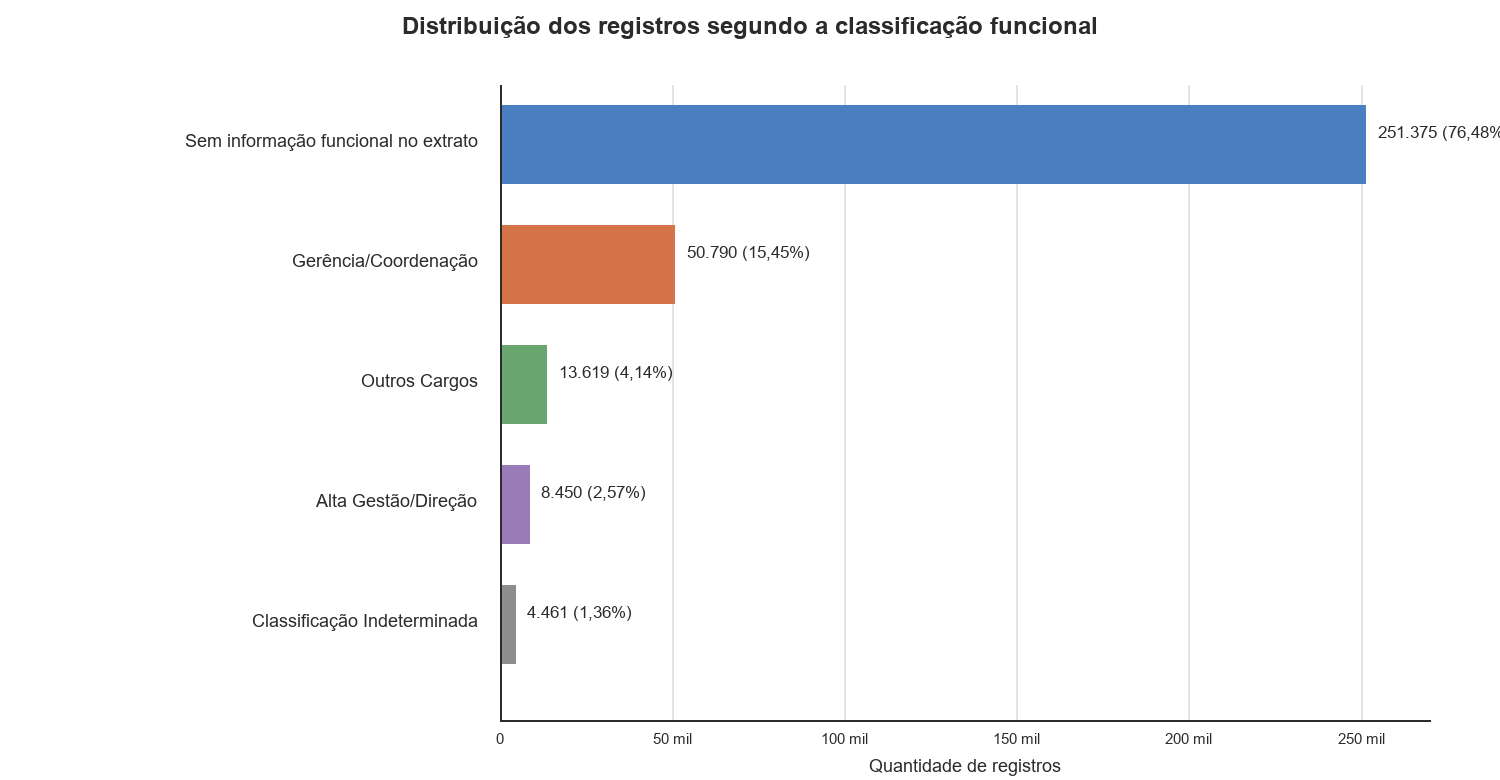

In [24]:
# Criar o gráfico de barras (cargo_summary_df_updated vem da célula anterior)
plt.figure(figsize=FIGSIZE_AMPLO)
sns.barplot(
    x='Quantidade',
    y=cargo_summary_df_updated.index,
    data=cargo_summary_df_updated,
    palette=PALETA_CATEGORICA[:len(cargo_summary_df_updated)],
    hue=cargo_summary_df_updated.index,  # y atribuído ao hue para evitar aviso de depreciação
    legend=False  # sem legenda, pois o hue já corresponde ao eixo y
)

# Adicionar os valores (Quantidade e Percentual) nas barras
for index, row in cargo_summary_df_updated.iterrows():
    plt.text(row['Quantidade'] + 1000,  # deslocamento para melhor visibilidade
             index,  # posição no eixo y (rótulo da categoria)
             f'{row["Quantidade"]:,.0f} ({row["Percentual (%)"]:.2f}%)',
             color='black', ha="left", va='center', fontsize=10)

plt.title('Distribuição dos Registros segundo a Classificação Funcional')
plt.xlabel('Quantidade de Servidores')
plt.ylabel('Classificação Funcional')
plt.grid(axis='x', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

In [25]:
# Distribuição funcional por grupo racial, com percentuais calculados dentro de cada grupo.
df_filtered_raca = df_cleaned[df_cleaned['raca_cor_agrupada'].isin(['BRANCA', 'NEGROS'])].copy()
tab_cargo_raca = pd.crosstab(df_filtered_raca['cargo_hierarquico'], df_filtered_raca['raca_cor_agrupada'])
tab_cargo_raca = tab_cargo_raca.reindex(CATEGORIAS_HIERARQUICAS, fill_value=0)
percentuais_por_grupo = (tab_cargo_raca / tab_cargo_raca.sum(axis=0) * 100).round(2)

print('Contagens por classificação funcional e grupo racial:')
display(tab_cargo_raca)
print('Percentuais dentro de cada grupo racial:')
display(percentuais_por_grupo)

# Gráfico auxiliar; a tabela é a referência para o artigo.
df_plot_cargo_raca = tab_cargo_raca.stack().reset_index(name='Quantidade')
df_plot_cargo_raca.columns = ['Classificação Funcional', 'Grupo Racial', 'Quantidade']
plt.figure(figsize=FIGSIZE_AMPLO)
sns.barplot(x='Classificação Funcional', y='Quantidade', hue='Grupo Racial',
            data=df_plot_cargo_raca, palette=PALETA_RACA,
            order=CATEGORIAS_HIERARQUICAS, hue_order=['BRANCA', 'NEGROS'])
plt.title('Distribuição Funcional por Grupo Racial')
plt.xlabel('Classificação Funcional')
plt.ylabel('Quantidade de Registros')
plt.xticks(rotation=15, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()


Contagens por classificação funcional e grupo racial:
Grupo racial                              BRANCA  NEGROS
Alta Gestão/Direção                         5757    2693
Gerência/Coordenação                       31744   19046
Outros Cargos                               7915    5704
Classificação Indeterminada                 2714    1747
Sem informação funcional no extrato       147443  103932

Percentuais dentro de cada grupo racial:
Grupo racial                              BRANCA  NEGROS
Alta Gestão/Direção                         2.94    2.02
Gerência/Coordenação                       16.23   14.31
Outros Cargos                               4.05    4.28
Classificação Indeterminada                 1.39    1.31
Sem informação funcional no extrato        75.39   78.07


## 3.3. Distribuição por Sexo e Grupo Racial

Verificando a representatividade de homens e mulheres autodeclarados pretos, pardos e brancos em `df_cleaned`.

Distribuição de Servidores por Grupo Racial e Sexo :



,Grupo,Quantidade,Percentual (%)
0,Negros Homens,75407,22.941329
1,Negras Mulheres,57715,17.558831
2,Brancos Homens,104648,31.837418
3,Brancas Mulheres,90925,27.662423


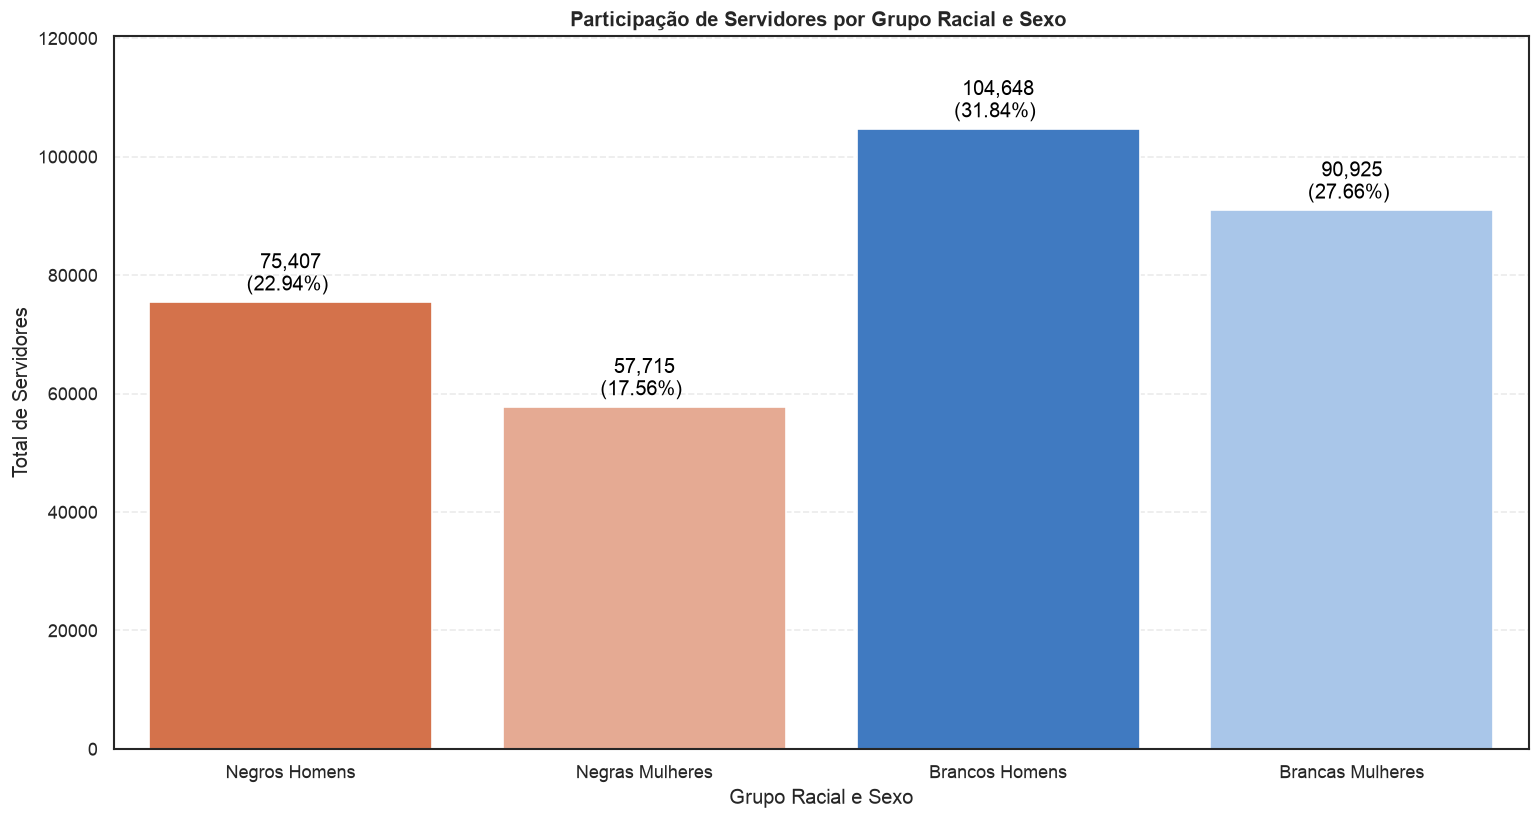

In [26]:
# df_cleaned já não contém 'Não Informado'/NaN em raca_cor neste ponto do pipeline
# (removidos na Seção 2.2.1), então não é necessário nenhum fallback para 'Brancos'.
df_temp_sexo_raca = df_cleaned.copy()
df_temp_sexo_raca['grupo_racial'] = df_temp_sexo_raca['raca_cor'].apply(
    lambda x: 'Negros' if x in ['PRETA', 'PARDA'] else 'Brancos'
)

def get_correct_group_name(row):
    if row['grupo_racial'] == 'Negros':
        return 'Negros Homens' if row['sexo'] == 'M' else 'Negras Mulheres'
    else:
        return 'Brancos Homens' if row['sexo'] == 'M' else 'Brancas Mulheres'

df_temp_sexo_raca['final_grupo'] = df_temp_sexo_raca.apply(get_correct_group_name, axis=1)

total_servidores_original = df_temp_sexo_raca.shape[0]
desired_order = ['Negros Homens', 'Negras Mulheres', 'Brancos Homens', 'Brancas Mulheres']

counts_sex_race = df_temp_sexo_raca['final_grupo'].value_counts().reset_index()
counts_sex_race.columns = ['Grupo', 'Quantidade']
counts_sex_race['Percentual (%)'] = (counts_sex_race['Quantidade'] / total_servidores_original) * 100
counts_sex_race['Grupo'] = pd.Categorical(counts_sex_race['Grupo'], categories=desired_order, ordered=True)
counts_sex_race = counts_sex_race.sort_values('Grupo').reset_index(drop=True)

print("Distribuição de Servidores por Grupo Racial e Sexo :\n")
display(counts_sex_race)

# Gerar o gráfico de barras (Gráfico 5) - mantém a identidade racial
# (azul=Brancos, laranja=Negros), com tom mais claro para o sexo feminino
cores_sexo_raca = {
    'Brancos Homens': COR_BRANCA,
    'Brancas Mulheres': '#9ec5f4',
    'Negros Homens': COR_NEGROS,
    'Negras Mulheres': '#f3a485',
}
plt.figure(figsize=FIGSIZE_AMPLO)
sns.barplot(x='Grupo', y='Quantidade', data=counts_sex_race, palette=cores_sexo_raca, hue='Grupo', dodge=False, legend=False)

for index, row in counts_sex_race.iterrows():
    plt.text(index, row['Quantidade'] + counts_sex_race['Quantidade'].max() * 0.01,
             f"{int(row['Quantidade']):,}\n({row['Percentual (%)']:.2f}%) ",
             color='black', ha="center", va='bottom')

plt.ylim(0, counts_sex_race['Quantidade'].max() * 1.15)

plt.title('Participação de Servidores por Grupo Racial e Sexo ')
plt.xlabel('Grupo Racial e Sexo')
plt.ylabel('Total de Servidores')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()


### 4.1. Definição das Variáveis Temporais (Período Pré e Pós-Cotas, 2015-2022)

Ao invés de criar DataFrames distintos, vamos criar uma nova coluna em `df_cleaned` para discriminar os registros entre 'Pré-Cotas' e 'Pós-Cotas'.

Definiremos os intervalos de datas para cada período e atribuiremos os valores correspondentes à nova coluna `periodo_cotas`.

In [27]:
# Definir os intervalos de datas
# Derivado das constantes globais (célula 1.1.1) - fonte única de verdade,
# evita reintroduzir o bug de boundary já corrigido (ver Analise_Notebook_SIAPE, item A1)
inicio_pre_cotas = pd.to_datetime(f'{ANO_INICIO_PRE_COTAS}-01-01')
fim_pre_cotas = pd.to_datetime(f'{ANO_FIM_PRE_COTAS}-12-31')

inicio_pos_cotas = pd.to_datetime(f'{ANO_INICIO_POS_COTAS}-01-01')
fim_pos_cotas = pd.to_datetime(f'{ANO_FIM_POS_COTAS}-12-31')

# Criar as condições
condicoes = [
    (df_cleaned['data_admissao'] >= inicio_pre_cotas) & (df_cleaned['data_admissao'] <= fim_pre_cotas),
    (df_cleaned['data_admissao'] >= inicio_pos_cotas) & (df_cleaned['data_admissao'] <= fim_pos_cotas)
]

# Definir os valores correspondentes
valores = ['Pré-Cotas', 'Pós-Cotas']

# Criar a nova coluna 'periodo_cotas'
df_cleaned['periodo_cotas'] = np.select(condicoes, valores, default='Outro Período')

# Verificar a contagem de valores da nova coluna
print("Contagem de valores para 'periodo_cotas':")

# Calcular contagens e percentuais
periodo_counts = df_cleaned['periodo_cotas'].value_counts()

periodo_percentages = (periodo_counts / periodo_counts.sum() * 100).round(2)

periodo_summary_df = pd.DataFrame({
    'Quantidade': periodo_counts,
    'Percentual (%)': periodo_percentages
})
print(f"Shape de df_cleaned: {df_cleaned.shape}")
display(periodo_summary_df)

Contagem de valores para 'periodo_cotas':
Shape de df_cleaned: (328695, 14)


,Quantidade,Percentual (%)
periodo_cotas,,
Pré-Cotas,193721,58.94
Pós-Cotas,81624,24.83
Outro Período,53350,16.23


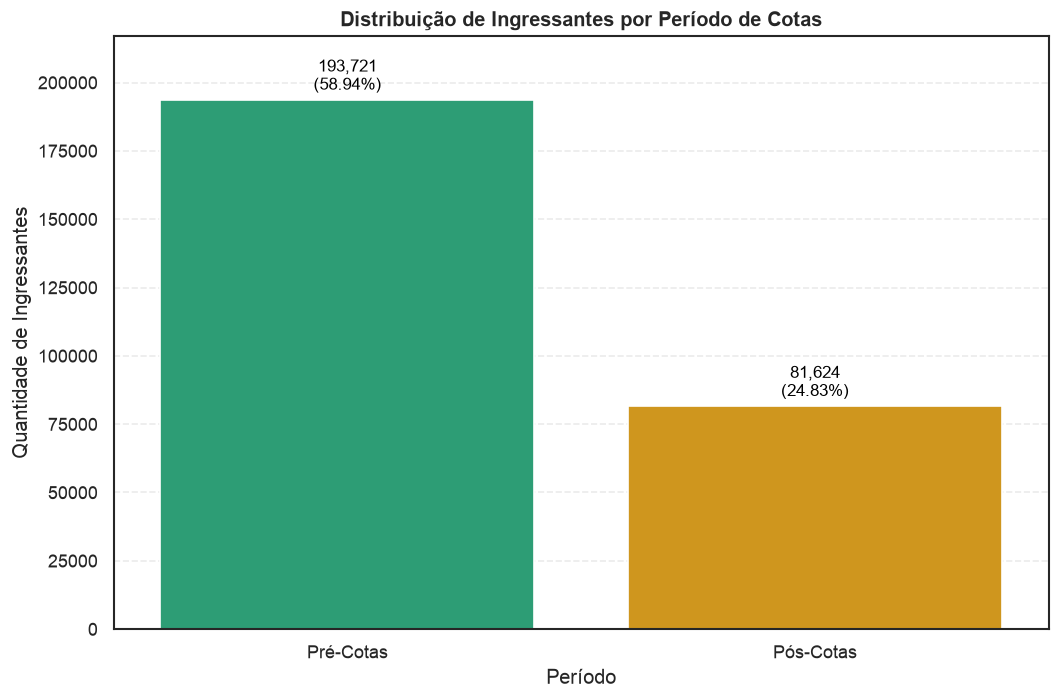

In [28]:
# Remover 'Outro Período' do dataframe
periodo_summary_df_filtered = periodo_summary_df[periodo_summary_df.index != 'Outro Período']

# Criar o gráfico de barras para periodo_summary_df_filtered
plt.figure(figsize=FIGSIZE_SIMPLES)
sns.barplot(
    x=periodo_summary_df_filtered.index,
    y='Quantidade',
    data=periodo_summary_df_filtered,
    palette=PALETA_CATEGORICA[2:4],
    hue=periodo_summary_df_filtered.index,  # index atribuído ao hue para evitar aviso de depreciação
    legend=False  # sem legenda, pois o hue já corresponde ao eixo x
)

# Adicionar os valores absolutos e percentuais nas barras
for index, row in periodo_summary_df_filtered.iterrows():
    plt.text(periodo_summary_df_filtered.index.get_loc(index), row['Quantidade'] + (periodo_summary_df_filtered['Quantidade'].max() * 0.01),
             f"{int(row['Quantidade']):,}\n({row['Percentual (%)']:.2f}%)",
             color='black', ha="center", va='bottom', fontsize=10)

plt.title('Distribuição de Ingressantes por Período de Cotas')
plt.xlabel('Período')
plt.ylabel('Quantidade de Ingressantes')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

In [29]:
# Tabulação por período e grupo racial
periodo_order = ['Pré-Cotas', 'Pós-Cotas']
raca_order = ['BRANCA', 'NEGROS']

df_raca_periodo = df_cleaned[
    df_cleaned['raca_cor_agrupada'].isin(raca_order) &
    df_cleaned['periodo_cotas'].isin(periodo_order)
].copy()

tab_periodo_raca = pd.crosstab(
    df_raca_periodo['periodo_cotas'],
    df_raca_periodo['raca_cor_agrupada']
).reindex(index=periodo_order, columns=raca_order, fill_value=0)

# Percentuais calculados dentro de cada período, adequados à comparação racial
tab_periodo_raca_percent = tab_periodo_raca.div(
    tab_periodo_raca.sum(axis=1), axis=0
).mul(100).round(2)

tab_final_periodo_raca = pd.DataFrame(index=periodo_order, columns=raca_order + ['Total'])
for periodo in periodo_order:
    for raca in raca_order:
        quantidade = tab_periodo_raca.loc[periodo, raca]
        percentual = tab_periodo_raca_percent.loc[periodo, raca]
        tab_final_periodo_raca.loc[periodo, raca] = f"{quantidade:,} ({percentual:.2f}%)"
    tab_final_periodo_raca.loc[periodo, 'Total'] = f"{tab_periodo_raca.loc[periodo].sum():,} (100.00%)"

print("Ingressantes por período e grupo racial (percentuais dentro de cada período):\n")
display(tab_final_periodo_raca)


Ingressantes por período e grupo racial (percentuais dentro de cada período):



,BRANCA,NEGROS,Total
Pré-Cotas,"122,211 (63.09%)","71,510 (36.91%)","193,721 (100.00%)"
Pós-Cotas,"45,831 (56.15%)","35,793 (43.85%)","81,624 (100.00%)"


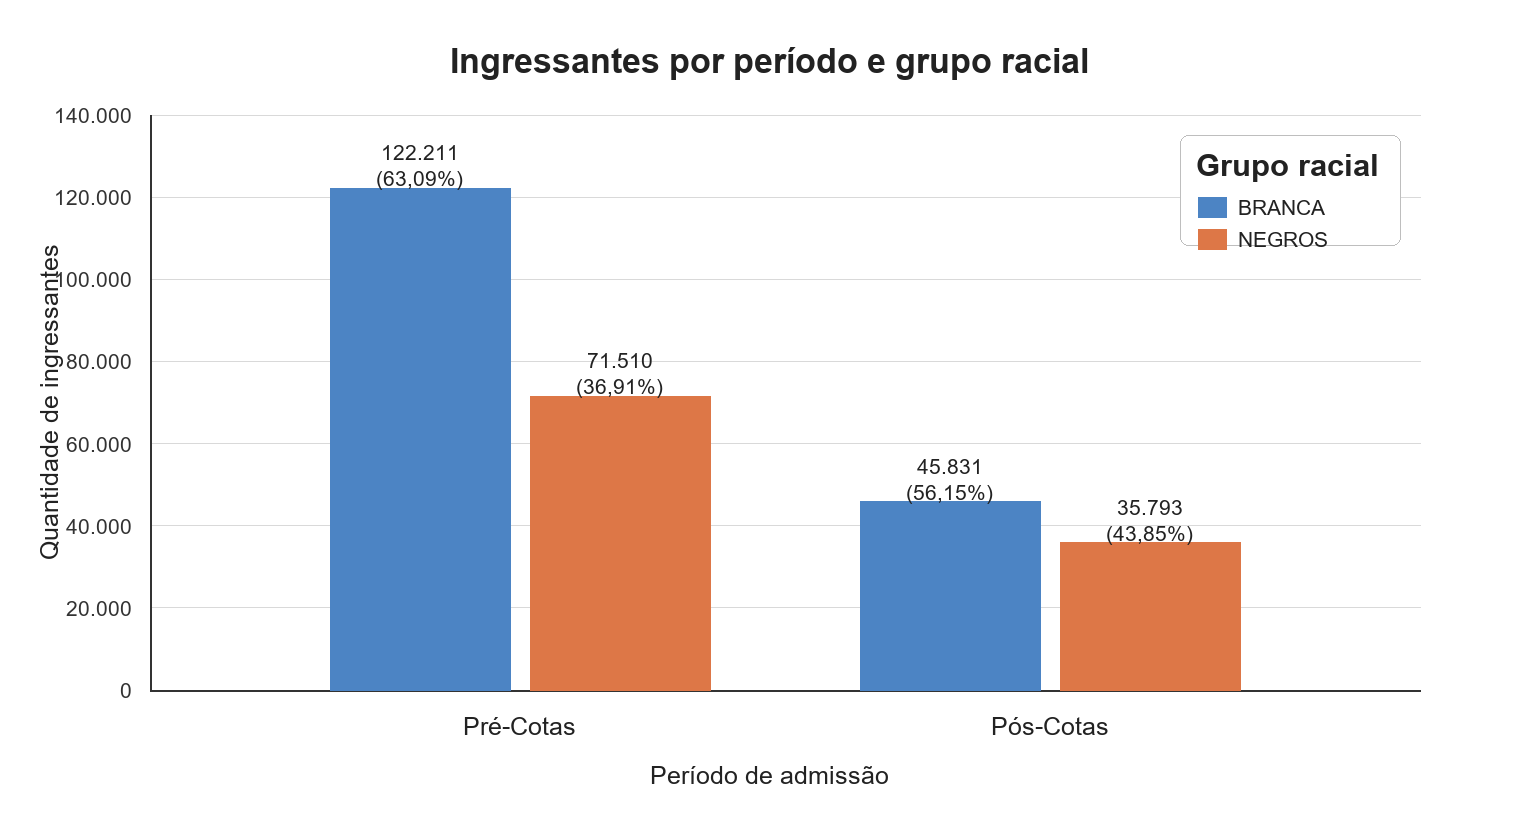

In [30]:
# Preparar os dados para o gráfico
df_plot_melted = tab_periodo_raca.stack().rename('Quantidade').reset_index()
df_plot_melted.columns = ['Periodo_Cotas', 'Raca_Cor_Agrupada', 'Quantidade']
df_plot_melted['Percentual (%)'] = df_plot_melted.apply(
    lambda row: tab_periodo_raca_percent.loc[row['Periodo_Cotas'], row['Raca_Cor_Agrupada']],
    axis=1
)

plt.figure(figsize=FIGSIZE_AMPLO)
ax = sns.barplot(
    x='Periodo_Cotas',
    y='Quantidade',
    hue='Raca_Cor_Agrupada',
    data=df_plot_melted,
    palette=PALETA_RACA,
    order=periodo_order,
    hue_order=raca_order
)

# Rótulos: quantidade absoluta e percentual dentro do respectivo período
for container_idx, container in enumerate(ax.containers):
    raca = raca_order[container_idx]
    for bar_idx, bar in enumerate(container.patches):
        periodo = periodo_order[bar_idx]
        quantidade = int(tab_periodo_raca.loc[periodo, raca])
        percentual = tab_periodo_raca_percent.loc[periodo, raca]
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + tab_periodo_raca.to_numpy().max() * 0.015,
            f"{quantidade:,}\n({percentual:.2f}%)",
            ha='center', va='bottom', fontsize=9, color='black'
        )

plt.title('Ingressantes por período e grupo racial')
plt.xlabel('Período de admissão')
plt.ylabel('Quantidade de ingressantes')
plt.legend(title='Grupo racial')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()


### 4.2. Teste de Significância: Diferença na Proporção de Ingressantes Negros entre Períodos

Antes de avançar para a análise descritiva por período, testamos formalmente se a diferença observada na proporção de ingressantes negros entre o Período Pré-Cotas e o Período Pós-Cotas é estatisticamente significativa, e não apenas variação amostral.

**Por que um teste de duas proporções, e não um teste t sobre as médias anuais:** os valores anuais representam o número de ingressantes (fluxo de admissões) em cada ano, com tamanhos de amostra muito distintos entre os anos (de pouco mais de 1.000 a mais de 21.000 admissões/ano) e entre os dois períodos (25 anos vs. 8 anos). Um teste t sobre as médias anuais trataria cada ano como uma observação de peso igual, ignorando o volume real de admissões em cada ano e a autocorrelação da série temporal. Por isso, aplicamos um **teste z de duas proporções** aos totais agregados de ingressantes de cada período, ponderando cada admissão individual pelo seu peso real na amostra.

In [31]:
from math import erfc, sqrt

# Teste z para duas proporções: participação negra no Pós-Cotas versus Pré-Cotas.
tabela_2x2 = tab_periodo_raca.loc[['Pré-Cotas', 'Pós-Cotas'], ['BRANCA', 'NEGROS']]
negros_pre = tabela_2x2.loc['Pré-Cotas', 'NEGROS']
total_pre = tabela_2x2.loc['Pré-Cotas'].sum()
negros_pos = tabela_2x2.loc['Pós-Cotas', 'NEGROS']
total_pos = tabela_2x2.loc['Pós-Cotas'].sum()

prop_pre = negros_pre / total_pre
prop_pos = negros_pos / total_pos
diferenca = prop_pos - prop_pre
prop_agrupada = (negros_pre + negros_pos) / (total_pre + total_pos)
erro_padrao_teste = sqrt(prop_agrupada * (1 - prop_agrupada) * (1 / total_pre + 1 / total_pos))
z_stat = diferenca / erro_padrao_teste
p_valor = erfc(abs(z_stat) / sqrt(2))

erro_padrao_dif = sqrt(prop_pre*(1-prop_pre)/total_pre + prop_pos*(1-prop_pos)/total_pos)
ic_95 = (diferenca - 1.96*erro_padrao_dif, diferenca + 1.96*erro_padrao_dif)

print(f'Proporção negra - Pré-Cotas: {prop_pre*100:.2f}% (n={total_pre:,})')
print(f'Proporção negra - Pós-Cotas: {prop_pos*100:.2f}% (n={total_pos:,})')
print(f'Diferença: {diferenca*100:.2f} pontos percentuais')
print(f'IC95%: [{ic_95[0]*100:.2f}; {ic_95[1]*100:.2f}] pontos percentuais')
print(f'z = {z_stat:.2f}; p = {p_valor:.2e}')


Proporção negra - Pré-Cotas: 36.91% (n=193,721)
Proporção negra - Pós-Cotas: 43.85% (n=81,624)
Diferença: 6.94 pontos percentuais
IC95%: [6.53; 7.34] pontos percentuais
z = 34.09; p = 1.11e-254


### 5. Análise do Primeiro Específico: Padrões Históricos de Exclusão (Período Pré-Cotas)

#### 5.1. Estatística Descritiva Inicial: Proporções de Ingressantes Brancos e Negros (1990-2014)

Obs.: diferentemente da exposição de motivos do projeto de lei, o qual não cita explicitamente se na base de dados utilizada foram considerados somente os servidores ativos, se foram considerados servidores de todas as esferas (municipal, estadual e federal) este trabalho analisou os dados disponíveis no SIAPE, correspondente ao serviço público na esfera federal, somente de servidores ativos no ano de 2022. O estudo ainda, não observou somente a representatividade da população negra (pretos e pardos), mas antes, desconsiderou os registros que não declararam raça/cor, bem como os que se declararam indígenas e amarelos, fazendo o comparativo entre pretos e brancos.

Proporções de Ingressantes Brancos e Negros no Período Pré-Cotas (1990-2014):


,Quantidade,Percentual (%)
raca_cor_agrupada,,
BRANCA,122211,63.09
NEGROS,71510,36.91


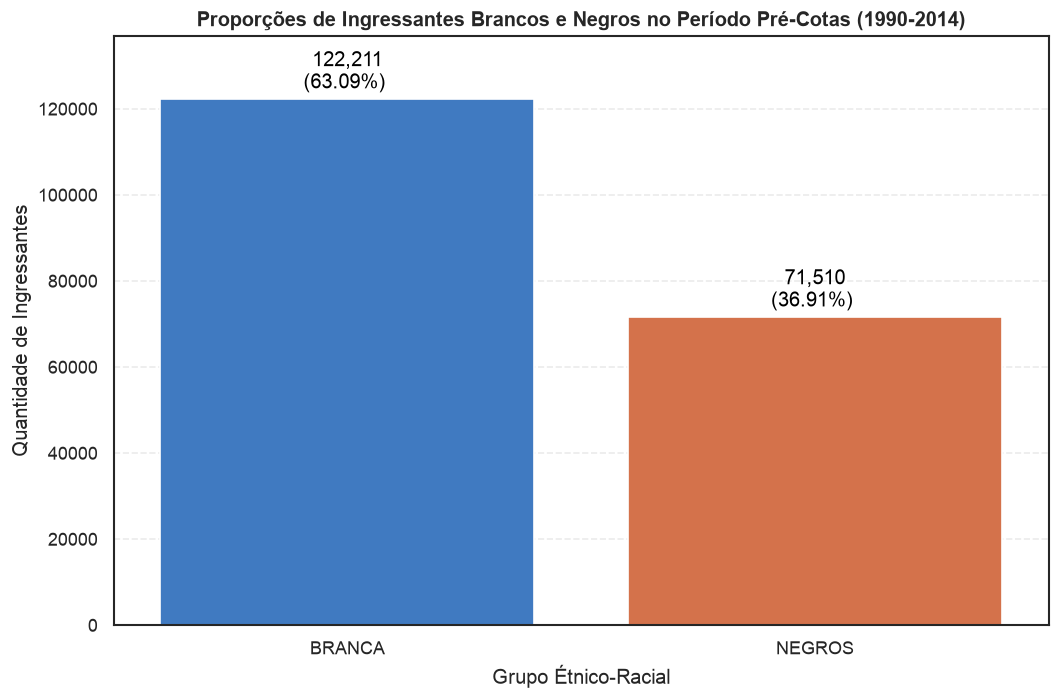

In [32]:
# Filtrar o DataFrame para o período 'Pré-Cotas' e as categorias 'BRANCA' e 'NEGROS'
df_pre_cotas_raca = df_cleaned[
    (df_cleaned['periodo_cotas'] == 'Pré-Cotas') &
    (df_cleaned['raca_cor_agrupada'].isin(['BRANCA', 'NEGROS']))
].copy()

# Calcular a contagem de cada grupo étnico-racial no período pré-cotas
counts_pre_cotas = df_pre_cotas_raca['raca_cor_agrupada'].value_counts()
proporcoes_raca_pre_cotas = df_pre_cotas_raca['raca_cor_agrupada'].value_counts(normalize=True).mul(100).round(2)

# Criar um DataFrame combinando contagens e percentuais
df_proporcoes_pre_cotas = pd.DataFrame({
    'Quantidade': counts_pre_cotas,
    'Percentual (%)': proporcoes_raca_pre_cotas
})

print(f"Proporções de Ingressantes Brancos e Negros no Período Pré-Cotas ({ANO_INICIO_PRE_COTAS}-{ANO_FIM_PRE_COTAS}):")
display(df_proporcoes_pre_cotas)

# Gerar o gráfico de barras

plt.figure(figsize=FIGSIZE_SIMPLES)
sns.barplot(
    x=df_proporcoes_pre_cotas.index,
    y='Quantidade',
    data=df_proporcoes_pre_cotas,
    palette=PALETA_RACA,
    hue=df_proporcoes_pre_cotas.index,
    legend=False
)

# Adicionar os valores absolutos e percentuais nas barras
for index, row in df_proporcoes_pre_cotas.iterrows():
    plt.text(index, row['Quantidade'] + df_proporcoes_pre_cotas['Quantidade'].max() * 0.01,
             f"{int(row['Quantidade']):,}\n({row['Percentual (%)']:.2f}%) ",
             color='black', ha="center", va='bottom')

plt.title(f'Proporções de Ingressantes Brancos e Negros no Período Pré-Cotas ({ANO_INICIO_PRE_COTAS}-{ANO_FIM_PRE_COTAS})')
plt.xlabel('Grupo Étnico-Racial')
plt.ylabel('Quantidade de Ingressantes')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

Proporções de Ingressantes Brancos e Negros no Período Pós-Cotas (2015-2022):


,Quantidade,Percentual (%)
raca_cor_agrupada,,
BRANCA,45831,56.15
NEGROS,35793,43.85


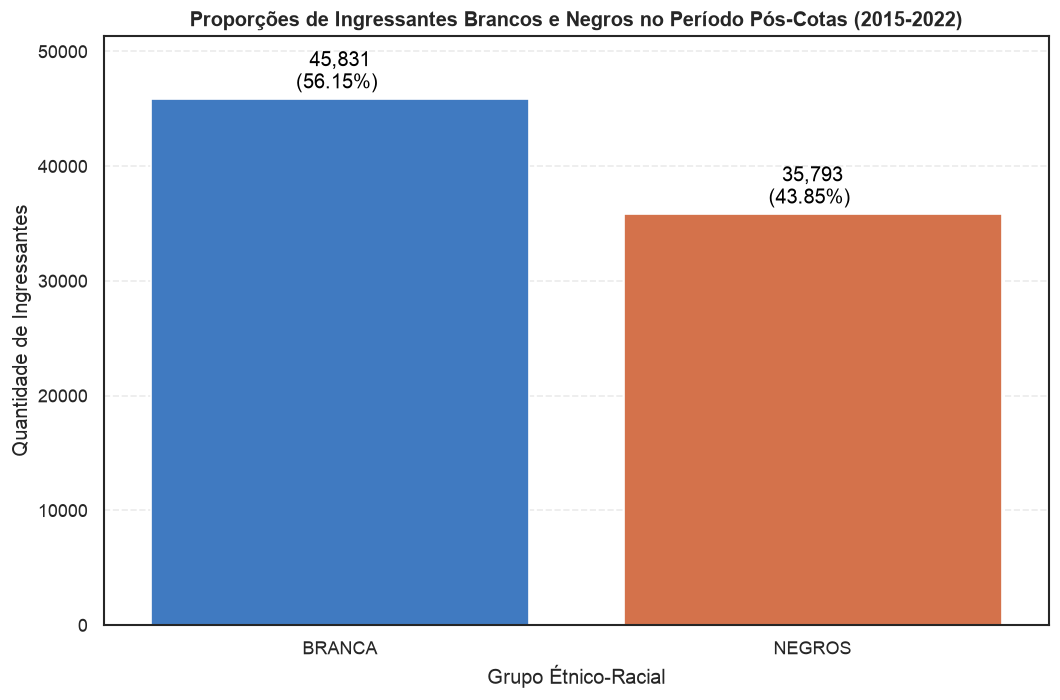

In [33]:
# Filtrar o DataFrame para o período 'Pós-Cotas' e as categorias 'BRANCA' e 'NEGROS'
df_pos_cotas_raca = df_cleaned[
    (df_cleaned['periodo_cotas'] == 'Pós-Cotas') &
    (df_cleaned['raca_cor_agrupada'].isin(['BRANCA', 'NEGROS']))
].copy()

# Calcular a contagem de cada grupo étnico-racial no período pós-cotas
counts_pos_cotas = df_pos_cotas_raca['raca_cor_agrupada'].value_counts()
proporcoes_raca_pos_cotas = df_pos_cotas_raca['raca_cor_agrupada'].value_counts(normalize=True).mul(100).round(2)

# Criar um DataFrame combinando contagens e percentuais
df_proporcoes_pos_cotas = pd.DataFrame({
    'Quantidade': counts_pos_cotas,
    'Percentual (%)': proporcoes_raca_pos_cotas
})

print(f"Proporções de Ingressantes Brancos e Negros no Período Pós-Cotas ({ANO_INICIO_POS_COTAS}-{ANO_FIM_POS_COTAS}):")
display(df_proporcoes_pos_cotas)

# Gerar o gráfico de barras

plt.figure(figsize=FIGSIZE_SIMPLES)
sns.barplot(
    x=df_proporcoes_pos_cotas.index,
    y='Quantidade',
    data=df_proporcoes_pos_cotas,
    palette=PALETA_RACA,
    hue=df_proporcoes_pos_cotas.index,
    legend=False
)

# Adicionar os valores absolutos e percentuais nas barras
for index, row in df_proporcoes_pos_cotas.iterrows():
    plt.text(index, row['Quantidade'] + df_proporcoes_pos_cotas['Quantidade'].max() * 0.01,
             f"{int(row['Quantidade']):,}\n({row['Percentual (%)']:.2f}%) ",
             color='black', ha="center", va='bottom')

plt.title(f'Proporções de Ingressantes Brancos e Negros no Período Pós-Cotas ({ANO_INICIO_POS_COTAS}-{ANO_FIM_POS_COTAS})')
plt.xlabel('Grupo Étnico-Racial')
plt.ylabel('Quantidade de Ingressantes')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

### 6. Análise do Segundo Objetivo Específico: Indicador de Representatividade (Período Pós-Cotas)

#### 6.1. Evolução Temporal de Ingressantes (Pós Cotas): Mapear, ano a ano, o volume e a percentagem de ingressantes negros no serviço público federal.

In [34]:
# Filtrar o DataFrame para o período 'Pós-Cotas' e as categorias 'BRANCA' e 'NEGROS'
df_pos_cotas_anual = df_cleaned[
    (df_cleaned['periodo_cotas'] == 'Pós-Cotas') &
    (df_cleaned['raca_cor_agrupada'].isin(['BRANCA', 'NEGROS']))
].copy()

# Agrupar por ano de admissão e raca_cor_agrupada e contar
contagem_anual_pos_cotas = df_pos_cotas_anual.groupby(['ano_admissao', 'raca_cor_agrupada']).size().unstack(fill_value=0)

# Calcular a percentagem de ingressantes negros por ano
contagem_anual_pos_cotas['Total'] = contagem_anual_pos_cotas['BRANCA'] + contagem_anual_pos_cotas['NEGROS']
contagem_anual_pos_cotas['Percentagem_Negros'] = (contagem_anual_pos_cotas['NEGROS'] / contagem_anual_pos_cotas['Total']) * 100

print("Evolução Anual de Ingressantes Brancos e Negros no Período Pós-Cotas (2015-2022):")
display(contagem_anual_pos_cotas)

# Filtrar o DataFrame para o período 'Pré-Cotas' e as categorias 'BRANCA' e 'NEGROS'
# (usa a mesma coluna periodo_cotas da Seção 4.1 - agora consistente com 1990-2014)
df_pre_cotas_anual = df_cleaned[
    (df_cleaned['periodo_cotas'] == 'Pré-Cotas') &
    (df_cleaned['raca_cor_agrupada'].isin(['BRANCA', 'NEGROS']))
].copy()

# Agrupar por ano de admissão e raca_cor_agrupada e contar
contagem_anual_pre_cotas = df_pre_cotas_anual.groupby(['ano_admissao', 'raca_cor_agrupada']).size().unstack(fill_value=0)

# Calcular a percentagem de ingressantes negros por ano
contagem_anual_pre_cotas['Total'] = contagem_anual_pre_cotas['BRANCA'] + contagem_anual_pre_cotas['NEGROS']
contagem_anual_pre_cotas['Percentagem_Negros'] = (contagem_anual_pre_cotas['NEGROS'] / contagem_anual_pre_cotas['Total']) * 100

print("\nEvolução Anual de Ingressantes Brancos e Negros no Período 1990-2014:")
display(contagem_anual_pre_cotas)


Evolução Anual de Ingressantes Brancos e Negros no Período Pós-Cotas (2015-2022):


raca_cor_agrupada,BRANCA,NEGROS,Total,Percentagem_Negros
ano_admissao,,,,
2015,7454,5490,12944,42.413473
2016,6937,5455,12392,44.020336
2017,6479,5354,11833,45.246345
2018,5010,3792,8802,43.081118
2019,5499,4005,9504,42.140152
2020,3830,3022,6852,44.103911
2021,6156,5006,11162,44.848593
2022,4466,3669,8135,45.101414



Evolução Anual de Ingressantes Brancos e Negros no Período 1990-2014:


raca_cor_agrupada,BRANCA,NEGROS,Total,Percentagem_Negros
ano_admissao,,,,
1990,954,748,1702,43.948296
1991,1269,759,2028,37.426036
1992,1722,1092,2814,38.805970
1993,2502,1397,3899,35.829700
1994,4168,2754,6922,39.786189
1995,4114,2792,6906,40.428613
1996,2575,1255,3830,32.767624
1997,2408,1169,3577,32.681018
1998,2152,865,3017,28.670865


In [35]:
media_percentagem_negros_pre_cotas = contagem_anual_pre_cotas['Percentagem_Negros'].mean()
desvio_padrao_percentagem_negros_pre_cotas = contagem_anual_pre_cotas['Percentagem_Negros'].std()

print(f"Média da Percentagem_Negros (Pré-Cotas): {media_percentagem_negros_pre_cotas:.2f}%")
print(f"Desvio Padrão da Percentagem_Negros (Pré-Cotas): {desvio_padrao_percentagem_negros_pre_cotas:.2f}%")

Média da Percentagem_Negros (Pré-Cotas): 35.30%
Desvio Padrão da Percentagem_Negros (Pré-Cotas): 4.54%


In [36]:
media_percentagem_negros_pos_cotas = contagem_anual_pos_cotas['Percentagem_Negros'].mean()
desvio_padrao_percentagem_negros_pos_cotas = contagem_anual_pos_cotas['Percentagem_Negros'].std()

print(f"Média da Percentagem_Negros (Pós-Cotas): {media_percentagem_negros_pos_cotas:.2f}%")
print(f"Desvio Padrão da Percentagem_Negros (Pós-Cotas): {desvio_padrao_percentagem_negros_pos_cotas:.2f}%")

Média da Percentagem_Negros (Pós-Cotas): 43.87%
Desvio Padrão da Percentagem_Negros (Pós-Cotas): 1.21%


In [37]:
# Sem filtro de período (todos os anos) - apenas restringe às categorias 'BRANCA' e 'NEGROS'
df_cotas_anual = df_cleaned[
    (df_cleaned['raca_cor_agrupada'].isin(['BRANCA', 'NEGROS']))
].copy()

# Agrupar por ano de admissão e raca_cor_agrupada e contar
contagem_anual = df_cotas_anual.groupby(['ano_admissao', 'raca_cor_agrupada']).size().unstack(fill_value=0)

# Calcular a percentagem de ingressantes negros por ano
contagem_anual['Total'] = contagem_anual['BRANCA'] + contagem_anual['NEGROS']
contagem_anual['Percentagem_Negros'] = (contagem_anual['NEGROS'] / contagem_anual['Total']) * 100

ano_min, ano_max = df_cotas_anual['ano_admissao'].min(), df_cotas_anual['ano_admissao'].max()
print(f"Evolução Anual de Ingressantes Brancos e Negros em todo o Período ({ano_min:.0f}-{ano_max:.0f}):")
display(contagem_anual)

Evolução Anual de Ingressantes Brancos e Negros em todo o Período (1960-2022):


raca_cor_agrupada,BRANCA,NEGROS,Total,Percentagem_Negros
ano_admissao,,,,
1960,2,0,2,0.000000
1961,0,1,1,100.000000
1963,1,0,1,0.000000
1964,2,2,4,50.000000
1965,1,5,6,83.333333
...,...,...,...,...
2018,5010,3792,8802,43.081118
2019,5499,4005,9504,42.140152
2020,3830,3022,6852,44.103911


In [38]:
# Preparo de dados usado pelo Gráfico 14 (célula seguinte) - percentual de
# Brancos e Negros por ano, em formato longo.
contagem_anual['Percentagem_Branca'] = (contagem_anual['BRANCA'] / contagem_anual['Total']) * 100

df_plot_percent_anual = contagem_anual.reset_index().melt(
    id_vars=['ano_admissao'],
    value_vars=['Percentagem_Branca', 'Percentagem_Negros'],
    var_name='Grupo Racial',
    value_name='Percentual (%)'
)
df_plot_percent_anual['Grupo Racial'] = df_plot_percent_anual['Grupo Racial'].replace({
    'Percentagem_Branca': 'BRANCA',
    'Percentagem_Negros': 'NEGROS'
})


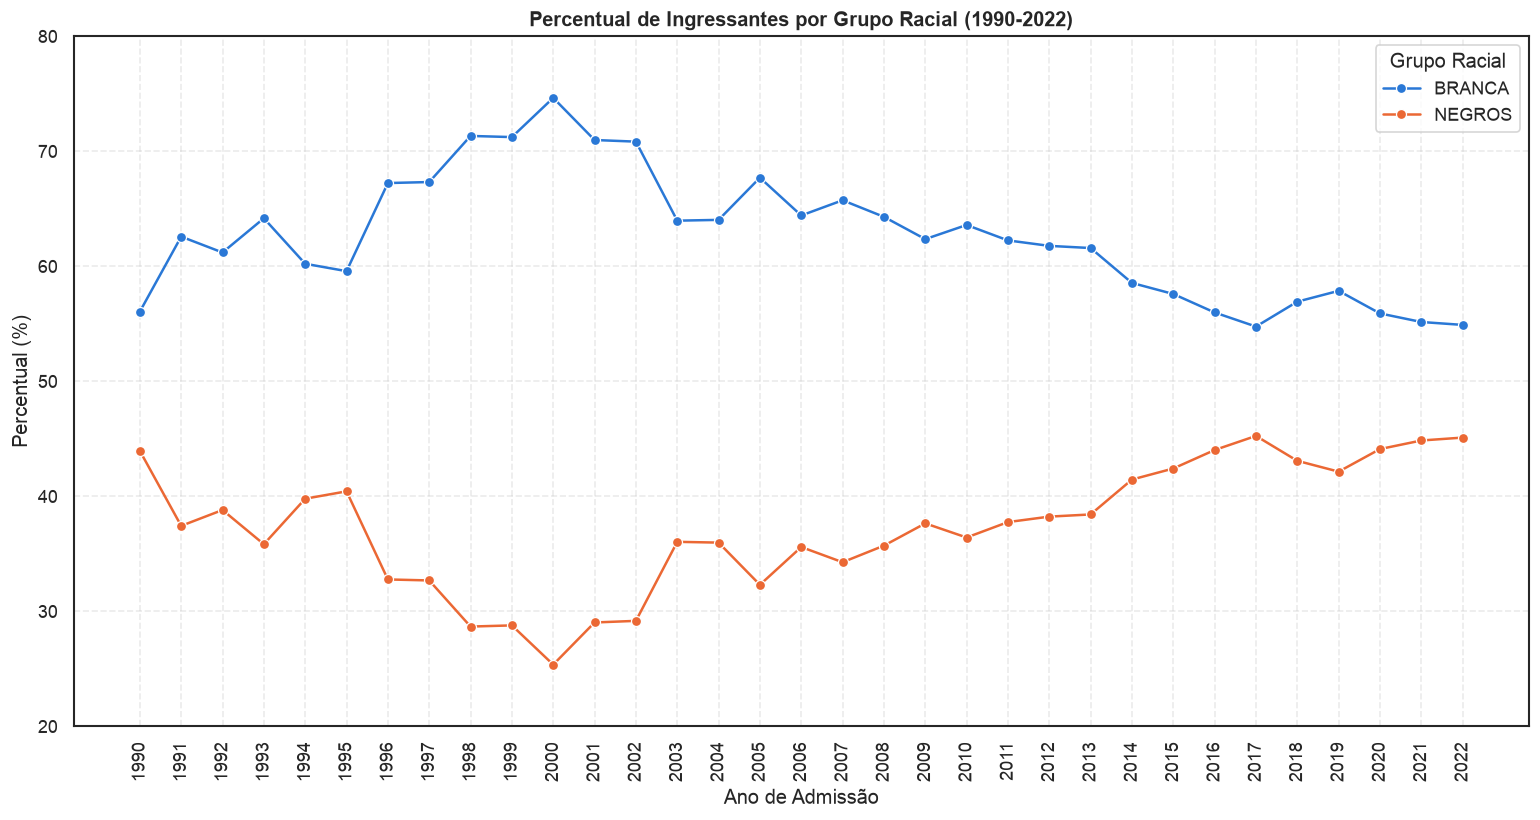

In [39]:
# Plotar a evolução temporal da percentagem de ingressantes negros (Gráfico 14)

df_plot_period_all = df_plot_percent_anual[
    (df_plot_percent_anual['ano_admissao'] >= ANO_INICIO_PRE_COTAS) &
    (df_plot_percent_anual['ano_admissao'] <= ANO_FIM_POS_COTAS)
].copy()

plt.figure(figsize=FIGSIZE_AMPLO)
sns.lineplot(
    x='ano_admissao',
    y='Percentual (%)',
    hue='Grupo Racial', # Added hue parameter
    data=df_plot_period_all,
    marker='o',
    palette=PALETA_RACA,
    )
plt.title(f'Percentual de Ingressantes por Grupo Racial ({ANO_INICIO_PRE_COTAS}-{ANO_FIM_POS_COTAS})')
plt.xlabel('Ano de Admissão')
plt.ylabel('Percentual (%)')
plt.grid(True, linestyle='--', alpha=0.4)
plt.xticks(df_plot_period_all['ano_admissao'].unique(), rotation=90)
plt.ylim(20, 80)
plt.tight_layout()
plt.show()

### 7. Análise do Terceiro Objetivo Específico: Renda e Segregação Ocupacional

#### 7.1. Análise do Indicador de Distribuição de Renda: Utilizar os níveis de função (nivel_funcao e atividade) como aproximação (proxy) de rendimento para comparar a média salarial/nível hierárquico entre o grupo de beneficiários (Negros) e o grupo de comparação (Brancos).

In [40]:
# Mapear 'cargo_hierarquico' para valores numéricos, criando um proxy de rendimento
# (MAPEAMENTO_HIERARQUICO_PROXY já definido na célula 1.1.1 - fonte única)
df_cleaned['proxy_renda_hierarquico'] = df_cleaned['cargo_hierarquico'].map(MAPEAMENTO_HIERARQUICO_PROXY)

# Filtrar o DataFrame para as categorias 'BRANCA' e 'NEGROS'
df_raca_hierarquia = df_cleaned[
    df_cleaned['raca_cor_agrupada'].isin(['BRANCA', 'NEGROS'])
].copy()

# Calcular a média do proxy de nível hierárquico por grupo étnico-racial
media_hierarquica_por_raca = df_raca_hierarquia.groupby('raca_cor_agrupada')['proxy_renda_hierarquico'].mean().reset_index()

print("Média do Nível Hierárquico Proxy por Raça/Cor:")
display(media_hierarquica_por_raca)

Média do Nível Hierárquico Proxy por Raça/Cor:


,raca_cor_agrupada,proxy_renda_hierarquico
0,BRANCA,0.939040
1,NEGROS,0.875711


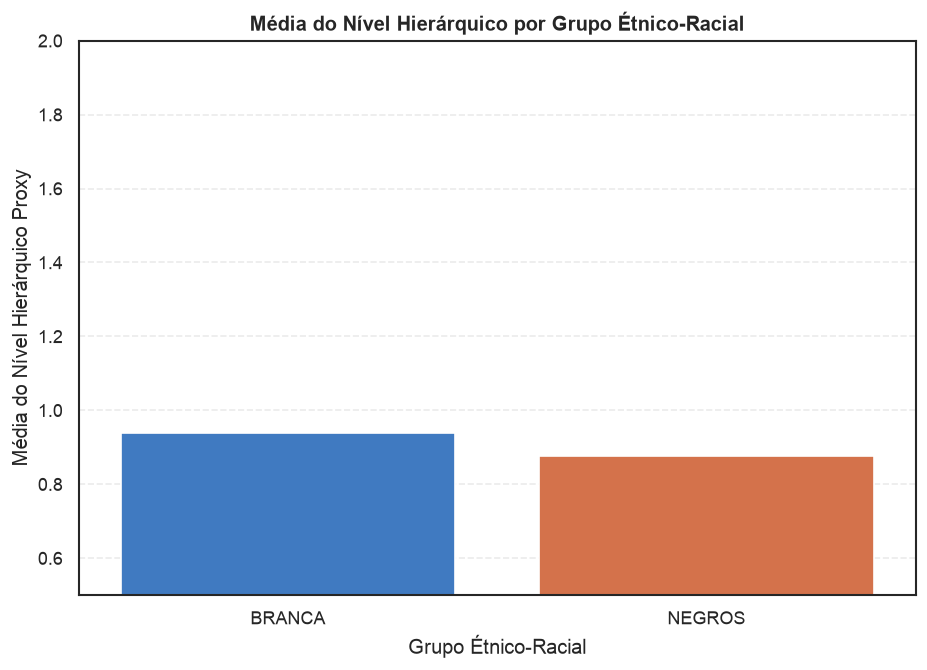

In [41]:
# Plotar a comparação da média do nível hierárquico proxy
plt.figure(figsize=FIGSIZE_SIMPLES)
sns.barplot(x='raca_cor_agrupada', y='proxy_renda_hierarquico', data=media_hierarquica_por_raca, palette=PALETA_RACA, hue='raca_cor_agrupada', legend=False)
plt.title('Média do Nível Hierárquico por Grupo Étnico-Racial')
plt.xlabel('Grupo Étnico-Racial')
plt.ylabel('Média do Nível Hierárquico Proxy')
plt.ylim(0.5, 2) # Definir limites para o proxy
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.show()

#### 7.2. Representação racial nas funções classificadas como liderança

Esta etapa descreve a composição racial das funções de Alta Gestão/Direção e Gerência/Coordenação observadas no extrato de 2022, segundo o período de admissão. Os resultados não indicam a posição ocupada no ingresso, promoção, mobilidade funcional ou remuneração.


In [42]:
# Definir as categorias de cargos de liderança
cargos_lideranca = ['Gerência/Coordenação', 'Alta Gestão/Direção']

# Filtrar o DataFrame para as categorias 'BRANCA' e 'NEGROS'
df_lideranca_raca = df_cleaned[
    df_cleaned['raca_cor_agrupada'].isin(['BRANCA', 'NEGROS'])
].copy()

# Calcular o total de indivíduos de cada grupo étnico-racial (referente ao total de BRANCA e NEGROS no dataset)
total_por_raca_no_df = df_lideranca_raca['raca_cor_agrupada'].value_counts()

# Filtrar os indivíduos em cargos de liderança (Gerência/Coordenação e Alta Gestão/Direção)
df_lideranca = df_lideranca_raca[
    df_lideranca_raca['cargo_hierarquico'].isin(cargos_lideranca)
]

# Calcular a contagem de indivíduos em cargos de liderança por raça
lideranca_por_raca = df_lideranca['raca_cor_agrupada'].value_counts()

# Percentagem de cada grupo racial sobre o total geral de cargos de liderança
total_lideranca_geral = lideranca_por_raca.sum()
percentagem_lideranca = (lideranca_por_raca / total_lideranca_geral) * 100

# Calcular a quantidade e percentagem para 'Alta Gestão/Direção'
df_alta_gestao_raca = df_lideranca_raca[
    df_lideranca_raca['cargo_hierarquico'] == 'Alta Gestão/Direção'
]
alta_gestao_por_raca = df_alta_gestao_raca['raca_cor_agrupada'].value_counts()
total_alta_gestao_geral = alta_gestao_por_raca.sum()
percentagem_alta_gestao = (alta_gestao_por_raca / total_alta_gestao_geral) * 100

# Calcular a quantidade e percentagem para 'Gerência/Coordenação'
df_gerencia_raca = df_lideranca_raca[
    df_lideranca_raca['cargo_hierarquico'] == 'Gerência/Coordenação'
]
gerencia_por_raca = df_gerencia_raca['raca_cor_agrupada'].value_counts()
total_gerencia_geral = gerencia_por_raca.sum()
percentagem_gerencia = (gerencia_por_raca / total_gerencia_geral) * 100

# Criar um DataFrame para exibir a quantidade absoluta e a percentagem
df_percentagem_lideranca = pd.DataFrame({
    'Quantidade Total Liderança': lideranca_por_raca,
    'Percentual Total Liderança (%)': percentagem_lideranca,
    'Quantidade Alta Gestão': alta_gestao_por_raca,
    'Percentual Alta Gestão (%)': percentagem_alta_gestao,
    'Quantidade Gerência/Coordenação': gerencia_por_raca,
    'Percentual Gerência/Coordenação (%)': percentagem_gerencia
})

print("Percentagem e Quantidade Absoluta de Registros em Funções de Liderança por Raça/Cor (Percentuais sobre o total da categoria):")
display(df_percentagem_lideranca.fillna(0).round(2).sort_index())


Composição racial das funções classificadas como liderança em toda a base:
         Liderança total  % liderança  Alta Gestão  % alta gestão  Gerência/Coordenação  % gerência
BRANCA             37501         63.30          5757           68.13                 31744        62.50
NEGROS             21739         36.70          2693           31.87                 19046        37.50


In [43]:
# Plotar a comparação da percentagem em cargos de liderança
plt.figure(figsize=FIGSIZE_SIMPLES)
ax = sns.barplot(x=percentagem_lideranca.index, y=percentagem_lideranca.values, palette=PALETA_RACA, hue=percentagem_lideranca.index, legend=False)
plt.title('Percentagem de Registros em Funções de Liderança por Grupo Étnico-Racial')
plt.xlabel('Grupo Étnico-Racial')
plt.ylabel('Participação no Total de Funções de Liderança (%)')

# Adicionar os valores (quantidade e percentual) em cima das barras
for index, p in enumerate(ax.patches):
    height = p.get_height()  # este é o percentual
    raca_label = percentagem_lideranca.index[index]

    # Obtém a quantidade absoluta de lideranca_por_raca
    quantidade = lideranca_por_raca[raca_label]

    ax.text(p.get_x() + p.get_width() / 2.,
            height + (percentagem_lideranca.max() * 0.01), # Pequeno deslocamento acima da barra
            f'{int(quantidade):,}\n({height:.2f}%)', # Formata a quantidade com separador de milhar e o percentual com 2 casas decimais
            ha='center', va='bottom', fontsize=10, color='black')

plt.ylim(0, percentagem_lideranca.max() * 1.1) # Ajustar limite y dinamicamente, começando de 0
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

In [44]:
# Plotar a comparação da percentagem em cargos de liderança

# 1. Filtra o DataFrame para o período Pré-Cotas e os grupos raciais
df_lideranca_time_filtered_1990_2014 = df_cleaned[
    (df_cleaned['ano_admissao'] >= ANO_INICIO_PRE_COTAS) &
    (df_cleaned['ano_admissao'] <= ANO_FIM_PRE_COTAS) &
    (df_cleaned['raca_cor_agrupada'].isin(['BRANCA', 'NEGROS']))
].copy()

# 2. Define as categorias de liderança
cargos_lideranca = ['Gerência/Coordenação', 'Alta Gestão/Direção']

# 3. Filtra os indivíduos em cargos de liderança dentro do período selecionado
df_lideranca_roles_1990_2014 = df_lideranca_time_filtered_1990_2014[
    df_lideranca_time_filtered_1990_2014['cargo_hierarquico'].isin(cargos_lideranca)
]

# 4. Calcula a contagem de cada grupo racial em cargos de liderança neste período
lideranca_por_raca_1990_2014 = df_lideranca_roles_1990_2014['raca_cor_agrupada'].value_counts()

# Garante que os dois grupos raciais estejam presentes, preenchendo com 0 se ausente
racial_groups = ['BRANCA', 'NEGROS']
lideranca_por_raca_1990_2014 = lideranca_por_raca_1990_2014.reindex(racial_groups, fill_value=0)

# 5. Calcula o percentual de cada grupo racial sobre o total de cargos de liderança neste período
total_lideranca_geral_1990_2014 = lideranca_por_raca_1990_2014.sum()

if total_lideranca_geral_1990_2014 > 0:
    percentagem_lideranca_1990_2014 = (lideranca_por_raca_1990_2014 / total_lideranca_geral_1990_2014) * 100
else:
    percentagem_lideranca_1990_2014 = pd.Series([0.0] * len(racial_groups), index=racial_groups)

# Usa essas variáveis para a plotagem
plt.figure(figsize=FIGSIZE_SIMPLES)
ax = sns.barplot(x=percentagem_lideranca_1990_2014.index, y=percentagem_lideranca_1990_2014.values, palette=PALETA_RACA, hue=percentagem_lideranca_1990_2014.index, legend=False)
plt.title('Percentagem de Registros em Funções de Liderança por Grupo Étnico-Racial (1990-2014)')
plt.xlabel('Grupo Étnico-Racial')
plt.ylabel('Participação no Total de Funções de Liderança (%)')

# Adicionar os valores (quantidade e percentual) em cima das barras
for index, p in enumerate(ax.patches):
    height = p.get_height()  # este é o percentual
    raca_label = percentagem_lideranca_1990_2014.index[index]

    # Obtém a quantidade absoluta de lideranca_por_raca_1990_2014
    quantidade = lideranca_por_raca_1990_2014[raca_label]

    ax.text(p.get_x() + p.get_width() / 2.,
            height + (percentagem_lideranca_1990_2014.max() * 0.01), # Pequeno deslocamento acima da barra
            f'{int(quantidade):,}\n({height:.2f}%)', # Formata a quantidade com separador de milhar e o percentual com 2 casas decimais
            ha='center', va='bottom', fontsize=10, color='black')

plt.ylim(0, percentagem_lideranca_1990_2014.max() * 1.1) # Ajustar limite y dinamicamente, começando de 0
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

Pré-Cotas - funções de liderança: BRANCA 25.932 (65,70%); NEGROS 13.539 (34,30%).


In [45]:
# Plotar a comparação da percentagem em cargos de liderança

# 1. Filtra o DataFrame para o período Pós-Cotas e os grupos raciais
df_lideranca_time_filtered_2015_2022 = df_cleaned[
    (df_cleaned['ano_admissao'] >= ANO_INICIO_POS_COTAS) &
    (df_cleaned['ano_admissao'] <= ANO_FIM_POS_COTAS) &
    (df_cleaned['raca_cor_agrupada'].isin(['BRANCA', 'NEGROS']))
].copy()

# 2. Define as categorias de liderança
cargos_lideranca = ['Gerência/Coordenação', 'Alta Gestão/Direção']

# 3. Filtra os indivíduos em cargos de liderança dentro do período selecionado
df_lideranca_roles_2015_2022 = df_lideranca_time_filtered_2015_2022[
    df_lideranca_time_filtered_2015_2022['cargo_hierarquico'].isin(cargos_lideranca)
]

# 4. Calcula a contagem de cada grupo racial em cargos de liderança neste período
lideranca_por_raca_2015_2022 = df_lideranca_roles_2015_2022['raca_cor_agrupada'].value_counts()

# Garante que os dois grupos raciais estejam presentes, preenchendo com 0 se ausente
racial_groups = ['BRANCA', 'NEGROS']
lideranca_por_raca_2015_2022 = lideranca_por_raca_2015_2022.reindex(racial_groups, fill_value=0)

# 5. Calcula o percentual de cada grupo racial sobre o total de cargos de liderança neste período
total_lideranca_geral_2015_2022 = lideranca_por_raca_2015_2022.sum()

if total_lideranca_geral_2015_2022 > 0:
    percentagem_lideranca_2015_2022 = (lideranca_por_raca_2015_2022 / total_lideranca_geral_2015_2022) * 100
else:
    percentagem_lideranca_2015_2022 = pd.Series([0.0] * len(racial_groups), index=racial_groups)

# Usa essas variáveis para a plotagem
plt.figure(figsize=FIGSIZE_SIMPLES)
ax = sns.barplot(x=percentagem_lideranca_2015_2022.index, y=percentagem_lideranca_2015_2022.values, palette=PALETA_RACA, hue=percentagem_lideranca_2015_2022.index, legend=False)
plt.title('Percentagem de Registros em Funções de Liderança por Grupo Étnico-Racial (2015-2022)')
plt.xlabel('Grupo Étnico-Racial')
plt.ylabel('Participação no Total de Funções de Liderança (%)')

# Adicionar os valores (quantidade e percentual) em cima das barras
for index, p in enumerate(ax.patches):
    height = p.get_height()  # este é o percentual
    raca_label = percentagem_lideranca_2015_2022.index[index]

    # Obtém a quantidade absoluta de lideranca_por_raca_2015_2022
    quantidade = lideranca_por_raca_2015_2022[raca_label]

    ax.text(p.get_x() + p.get_width() / 2.,
            height + (percentagem_lideranca_2015_2022.max() * 0.01), # Pequeno deslocamento acima da barra
            f'{int(quantidade):,}\n({height:.2f}%)', # Formata a quantidade com separador de milhar e o percentual com 2 casas decimais
            ha='center', va='bottom', fontsize=10, color='black')

plt.ylim(0, percentagem_lideranca_2015_2022.max() * 1.1) # Ajustar limite y dinamicamente, começando de 0
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

Pós-Cotas - funções de liderança: BRANCA 8.141 (57,62%); NEGROS 5.989 (42,38%).


#### 7.2.0. Gráfico: Total Agregado em Cargos de Liderança, Pré-Cotas vs. Pós-Cotas

Substitui os dois gráficos que antes mostravam esse total agregado separadamente por período (um painel dentro do Gráfico Combinado Pré-Cotas da Seção 5.3, e um gráfico isolado só para o Pós-Cotas), ambos com apenas 2 barras/2 números e redundantes com o gráfico "por nível hierárquico" que já compara os dois períodos lado a lado. Aqui os dois períodos passam a ser comparados em uma única figura.

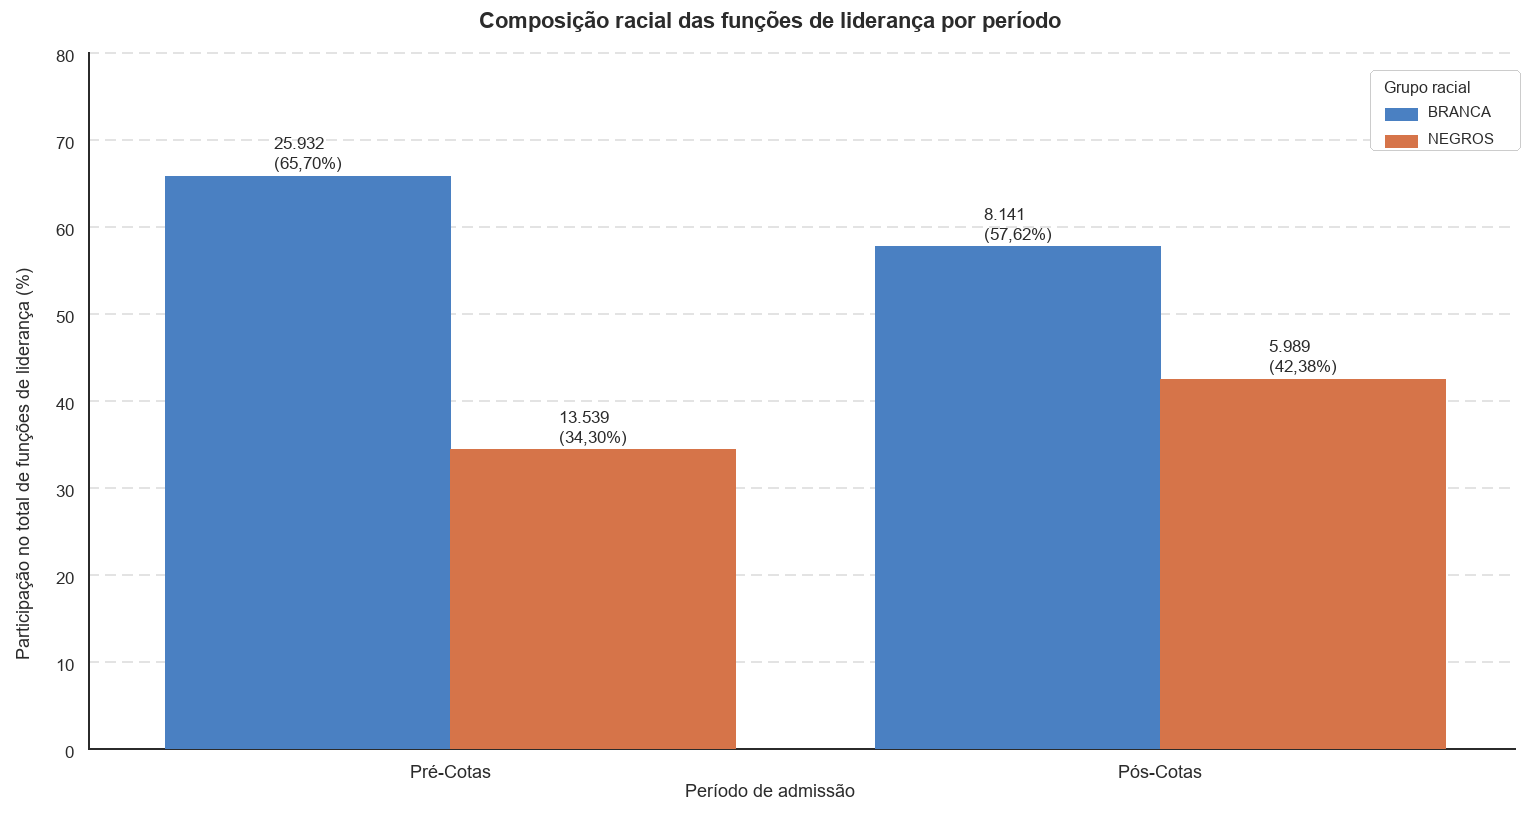

In [46]:
# Gráfico: Composição Racial das Funções de Liderança por Período
cargos_lideranca_types = ['Alta Gestão/Direção', 'Gerência/Coordenação']
racial_groups = ['BRANCA', 'NEGROS']

def _totais_lideranca(ano_ini, ano_fim):
    df_periodo = df_cleaned[
        (df_cleaned['ano_admissao'] >= ano_ini) &
        (df_cleaned['ano_admissao'] <= ano_fim) &
        (df_cleaned['raca_cor_agrupada'].isin(racial_groups)) &
        (df_cleaned['cargo_hierarquico'].isin(cargos_lideranca_types))
    ]
    contagem = df_periodo['raca_cor_agrupada'].value_counts().reindex(racial_groups, fill_value=0)
    total = contagem.sum()
    percentuais = (contagem / total * 100) if total > 0 else pd.Series([0.0] * len(racial_groups), index=racial_groups)
    return contagem, percentuais

contagem_pre, percentual_pre = _totais_lideranca(ANO_INICIO_PRE_COTAS, ANO_FIM_PRE_COTAS)
contagem_pos, percentual_pos = _totais_lideranca(ANO_INICIO_POS_COTAS, ANO_FIM_POS_COTAS)

df_plot_totais_lideranca = pd.DataFrame(
    [{'Periodo': 'Pré-Cotas', 'raca_cor_agrupada': raca, 'Quantidade': contagem_pre[raca], 'Percentual (%)': percentual_pre[raca]} for raca in racial_groups] +
    [{'Periodo': 'Pós-Cotas', 'raca_cor_agrupada': raca, 'Quantidade': contagem_pos[raca], 'Percentual (%)': percentual_pos[raca]} for raca in racial_groups]
)

periodo_order = ['Pré-Cotas', 'Pós-Cotas']
raca_order = ['BRANCA', 'NEGROS']

plt.figure(figsize=FIGSIZE_AMPLO)
ax = sns.barplot(
    x='Periodo', y='Percentual (%)', hue='raca_cor_agrupada',
    data=df_plot_totais_lideranca, palette=PALETA_RACA,
    order=periodo_order, hue_order=raca_order
)

for container_idx, container in enumerate(ax.containers):
    current_raca = raca_order[container_idx]
    for bar_idx, bar in enumerate(container.patches):
        height = bar.get_height()
        if height > 0:
            current_periodo = periodo_order[bar_idx]
            row = df_plot_totais_lideranca[
                (df_plot_totais_lideranca['Periodo'] == current_periodo) &
                (df_plot_totais_lideranca['raca_cor_agrupada'] == current_raca)
            ].iloc[0]
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                height + (ax.get_ylim()[1] * 0.01),
                f"{int(row['Quantidade']):,}\n({height:.2f}%)",
                ha='center', va='bottom', fontsize=10, color='black'
            )

plt.title('Composição Racial das Funções de Liderança por Período')
plt.xlabel('Período de Cotas')
plt.ylabel('Participação no Total de Funções de Liderança (%)')
plt.ylim(0, max(percentual_pre.max(), percentual_pos.max()) * 1.2)
plt.legend(title='Grupo Racial')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

#### 7.2.1. Análise Separada de Cargos de Gerência/Coordenação e Alta Gestão/Direção

In [47]:
# Filtra o DataFrame para o período Pré-Cotas
df_lideranca_1990_2014 = df_cleaned[
    (df_cleaned['ano_admissao'] >= ANO_INICIO_PRE_COTAS) &
    (df_cleaned['ano_admissao'] <= ANO_FIM_PRE_COTAS) &
    (df_cleaned['raca_cor_agrupada'].isin(['BRANCA', 'NEGROS']))
].copy()

cargos_lideranca_types = ['Alta Gestão/Direção', 'Gerência/Coordenação']
racial_groups = ['BRANCA', 'NEGROS']

data_for_plot = []

for cargo_type in cargos_lideranca_types:
    df_temp_cargo = df_lideranca_1990_2014[
        df_lideranca_1990_2014['cargo_hierarquico'] == cargo_type
    ]

    counts_by_raca = df_temp_cargo['raca_cor_agrupada'].value_counts()

    # Garante que os dois grupos raciais estejam presentes, preenchendo com 0 se ausente
    counts_by_raca = counts_by_raca.reindex(racial_groups, fill_value=0)

    total_for_cargo = counts_by_raca.sum()

    if total_for_cargo > 0:
        percentages_by_raca = (counts_by_raca / total_for_cargo) * 100
    else:
        percentages_by_raca = pd.Series([0.0] * len(racial_groups), index=racial_groups)

    for raca in racial_groups:
        data_for_plot.append({
            'raca_cor_agrupada': raca,
            'Quantidade': counts_by_raca[raca],
            'Tipo de Cargo': cargo_type,
            'Percentual (%)': percentages_by_raca[raca]
        })

df_plot_final_lideranca_time = pd.DataFrame(data_for_plot)

print("DataFrame 'df_plot_final_lideranca_time' utilizado na plotagem (Pré-Cotas):")
display(df_plot_final_lideranca_time)

# Define a ordem das categorias do eixo x
cargo_order = ['Alta Gestão/Direção', 'Gerência/Coordenação']
# Define explicitamente a ordem das categorias de hue
raca_order = ['BRANCA', 'NEGROS']

plt.figure(figsize=FIGSIZE_AMPLO)
ax = sns.barplot(
    x='Tipo de Cargo',
    y='Quantidade',
    hue='raca_cor_agrupada',
    data=df_plot_final_lideranca_time,
    palette=PALETA_RACA,
    order=cargo_order,
    hue_order=raca_order # Explicitly set hue order
)

# Adiciona valores absolutos e percentuais nas barras
for container_idx, container in enumerate(ax.containers):
    current_racial_group = raca_order[container_idx]

    for bar_idx, bar in enumerate(container.patches):
        height = bar.get_height()
        if height > 0:
            bar_center = bar.get_x() + bar.get_width() / 2

            current_cargo = cargo_order[bar_idx]

            # Obtém a linha de dados relevante para o percentual correto
            relevant_data = df_plot_final_lideranca_time[
                (df_plot_final_lideranca_time['Tipo de Cargo'] == current_cargo) &
                (df_plot_final_lideranca_time['raca_cor_agrupada'] == current_racial_group)
            ]

            if not relevant_data.empty:
                percentage = relevant_data['Percentual (%)'].iloc[0]
                ax.text(
                    bar_center,
                    height + (ax.get_ylim()[1] * 0.01), # Pequeno deslocamento acima da barra
                    f'{int(height):,}\n({percentage:.2f}%)', # Valor absoluto com separador de milhar e percentual
                    ha='center', va='bottom', fontsize=9, color='black'
                )

plt.title('Distribuição dos Registros em Funções de Liderança por Grupo Racial (1990-2014)')
plt.xlabel('Tipo de Cargo')
plt.ylabel('Quantidade de Servidores')
# Define o título da legenda gerada pelo seaborn
ax.legend_.set_title('Grupo Racial')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

Pré-Cotas:
Alta Gestão/Direção - BRANCA 4.217 (68,35%); NEGROS 1.953 (31,65%).
Gerência/Coordenação - BRANCA 21.715 (65,21%); NEGROS 11.586 (34,79%).


### 5.3. Gráfico Combinado: Liderança Pré-Cotas, Agregado e por Nível Hierárquico

Substitui a composição feita em LaTeX de duas imagens separadas lado a lado (que gerava desalinhamento de escala, margens excessivas e fontes pequenas demais para leitura), por uma única figura com dois painéis gerados na mesma escala e com fontes maiores, adequadas à exibição em página impressa.

In [48]:
# Gráfico combinado: Liderança (agregado e por nível hierárquico) - Período Pré-Cotas (1990-2014)
# Reaproveita as variáveis já calculadas nas células anteriores (percentagem_lideranca_1990_2014,
# lideranca_por_raca_1990_2014, df_plot_final_lideranca_time, cargo_order, raca_order).
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Painel 1: percentual agregado por grupo racial
sns.barplot(
    x=percentagem_lideranca_1990_2014.index,
    y=percentagem_lideranca_1990_2014.values,
    palette=PALETA_RACA,
    hue=percentagem_lideranca_1990_2014.index,
    legend=False,
    ax=ax1
)
ax1.set_title('Total (Agregado)', fontsize=15)
ax1.set_xlabel('Grupo Étnico-Racial', fontsize=13)
ax1.set_ylabel('Participação no Total de Funções de Liderança (%)', fontsize=13)
ax1.tick_params(axis='both', labelsize=12)
ax1.set_ylim(0, percentagem_lideranca_1990_2014.max() * 1.15)
for index, p in enumerate(ax1.patches):
    height = p.get_height()
    raca_label = percentagem_lideranca_1990_2014.index[index]
    quantidade = lideranca_por_raca_1990_2014[raca_label]
    ax1.text(p.get_x() + p.get_width() / 2., height + (percentagem_lideranca_1990_2014.max() * 0.02),
              f'{int(quantidade):,}\n({height:.2f}%)', ha='center', va='bottom', fontsize=12, color='black')
ax1.grid(axis='y', linestyle='--', alpha=0.4)

# Painel 2: por nível hierárquico (Alta Gestão/Direção e Gerência/Coordenação)
sns.barplot(
    x='Tipo de Cargo', y='Quantidade', hue='raca_cor_agrupada',
    data=df_plot_final_lideranca_time, palette=PALETA_RACA,
    order=cargo_order, hue_order=raca_order, ax=ax2
)
ax2.set_title('Por Nível Hierárquico', fontsize=15)
ax2.set_xlabel('Tipo de Cargo', fontsize=13)
ax2.set_ylabel('Quantidade de Servidores', fontsize=13)
ax2.tick_params(axis='both', labelsize=12)
ax2.legend(title='Grupo Racial', fontsize=11, title_fontsize=12)
for container_idx, container in enumerate(ax2.containers):
    current_racial_group = raca_order[container_idx]
    for bar_idx, bar in enumerate(container.patches):
        height = bar.get_height()
        if height > 0:
            current_cargo = cargo_order[bar_idx]
            relevant_data = df_plot_final_lideranca_time[
                (df_plot_final_lideranca_time['Tipo de Cargo'] == current_cargo) &
                (df_plot_final_lideranca_time['raca_cor_agrupada'] == current_racial_group)
            ]
            if not relevant_data.empty:
                percentage = relevant_data['Percentual (%)'].iloc[0]
                ax2.text(bar.get_x() + bar.get_width() / 2, height + (ax2.get_ylim()[1] * 0.015),
                          f'{int(height):,}\n({percentage:.2f}%)', ha='center', va='bottom', fontsize=11, color='black')
ax2.grid(axis='y', linestyle='--', alpha=0.4)

fig.suptitle('Proporção de Registros em Funções de Liderança por Grupo Étnico-Racial (1990-2014)', fontsize=16, y=1.03)
plt.tight_layout()
plt.show()

In [49]:
# Filtra o DataFrame para o período Pós-Cotas
df_lideranca_2015_2022 = df_cleaned[
    (df_cleaned['ano_admissao'] >= ANO_INICIO_POS_COTAS) &
    (df_cleaned['ano_admissao'] <= ANO_FIM_POS_COTAS) &
    (df_cleaned['raca_cor_agrupada'].isin(['BRANCA', 'NEGROS']))
].copy()

cargos_lideranca_types = ['Alta Gestão/Direção', 'Gerência/Coordenação']
racial_groups = ['BRANCA', 'NEGROS']

data_for_plot = []

for cargo_type in cargos_lideranca_types:
    df_temp_cargo = df_lideranca_2015_2022[
        df_lideranca_2015_2022['cargo_hierarquico'] == cargo_type
    ]

    counts_by_raca = df_temp_cargo['raca_cor_agrupada'].value_counts()

    # Garante que os dois grupos raciais estejam presentes, preenchendo com 0 se ausente
    counts_by_raca = counts_by_raca.reindex(racial_groups, fill_value=0)

    total_for_cargo = counts_by_raca.sum()

    if total_for_cargo > 0:
        percentages_by_raca = (counts_by_raca / total_for_cargo) * 100
    else:
        percentages_by_raca = pd.Series([0.0] * len(racial_groups), index=racial_groups)

    for raca in racial_groups:
        data_for_plot.append({
            'raca_cor_agrupada': raca,
            'Quantidade': counts_by_raca[raca],
            'Tipo de Cargo': cargo_type,
            'Percentual (%)': percentages_by_raca[raca]
        })

df_plot_final_lideranca_time = pd.DataFrame(data_for_plot)

print("DataFrame 'df_plot_final_lideranca_time' utilizado na plotagem (Pós-Cotas):")
display(df_plot_final_lideranca_time)

# Define a ordem das categorias do eixo x
cargo_order = ['Alta Gestão/Direção', 'Gerência/Coordenação']
# Define explicitamente a ordem das categorias de hue
raca_order = ['BRANCA', 'NEGROS']

plt.figure(figsize=FIGSIZE_AMPLO)
ax = sns.barplot(
    x='Tipo de Cargo',
    y='Quantidade',
    hue='raca_cor_agrupada',
    data=df_plot_final_lideranca_time,
    palette=PALETA_RACA,
    order=cargo_order,
    hue_order=raca_order # Explicitly set hue order
)

# Adiciona valores absolutos e percentuais nas barras
for container_idx, container in enumerate(ax.containers):
    current_racial_group = raca_order[container_idx]

    for bar_idx, bar in enumerate(container.patches):
        height = bar.get_height()
        if height > 0:
            bar_center = bar.get_x() + bar.get_width() / 2

            current_cargo = cargo_order[bar_idx]

            # Obtém a linha de dados relevante para o percentual correto
            relevant_data = df_plot_final_lideranca_time[
                (df_plot_final_lideranca_time['Tipo de Cargo'] == current_cargo) &
                (df_plot_final_lideranca_time['raca_cor_agrupada'] == current_racial_group)
            ]

            if not relevant_data.empty:
                percentage = relevant_data['Percentual (%)'].iloc[0]
                ax.text(
                    bar_center,
                    height + (ax.get_ylim()[1] * 0.01), # Pequeno deslocamento acima da barra
                    f'{int(height):,}\n({percentage:.2f}%)', # Valor absoluto com separador de milhar e percentual
                    ha='center', va='bottom', fontsize=9, color='black'
                )

plt.title('Distribuição dos Registros em Funções de Liderança por Grupo Racial (2015-2022)')
plt.xlabel('Tipo de Cargo')
plt.ylabel('Quantidade de Servidores')
# Define o título da legenda gerada pelo seaborn
ax.legend_.set_title('Grupo Racial')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

Pós-Cotas:
Alta Gestão/Direção - BRANCA 1.080 (65,10%); NEGROS 579 (34,90%).
Gerência/Coordenação - BRANCA 7.061 (56,62%); NEGROS 5.410 (43,38%).


### 8. Consolidação dos resultados recalculados

1. **Representatividade nas coortes:** a participação negra corresponde a **36,91%** no período 1990-2014 e a **43,85%** no período 2015-2022.
2. **Liderança no período 1990-2014:** pessoas negras representam **34,30%** das funções de liderança, **31,65%** da Alta Gestão/Direção e **34,79%** da Gerência/Coordenação.
3. **Liderança no período 2015-2022:** pessoas negras representam **42,38%** das funções de liderança, **34,90%** da Alta Gestão/Direção e **43,38%** da Gerência/Coordenação.
4. **Cobertura funcional:** 251.375 registros (**76,48%**) não apresentam função, nível e atividade no extrato; 4.461 registros (**1,36%**) possuem denominação insuficiente ou ambígua e permanecem indeterminados.
5. **Indicador hierárquico entre casos classificáveis:** média de **0,952** para brancos e **0,890** para negros, em escala de 0 a 2. Esse indicador não mede remuneração.

Os percentuais de liderança descrevem a composição racial dentro do total da categoria. A função corresponde à posição observada no extrato de 2022, e não à posição na admissão.


### 5.5. Gráfico Combinado: Funções de Liderança, Pré-Cotas vs. Pós-Cotas

Mesma correção aplicada ao gráfico de liderança agregado/por nível (Seção 5.3): substitui a composição em LaTeX de duas imagens separadas (uma por período), que gerava desalinhamento de escala e fontes pequenas, por uma única figura com dois painéis na mesma escala visual e fontes maiores. Recalcula os dois recortes (Pré e Pós-Cotas) com nomes de variável próprios, para não depender de variáveis compartilhadas sobrescritas em células anteriores.

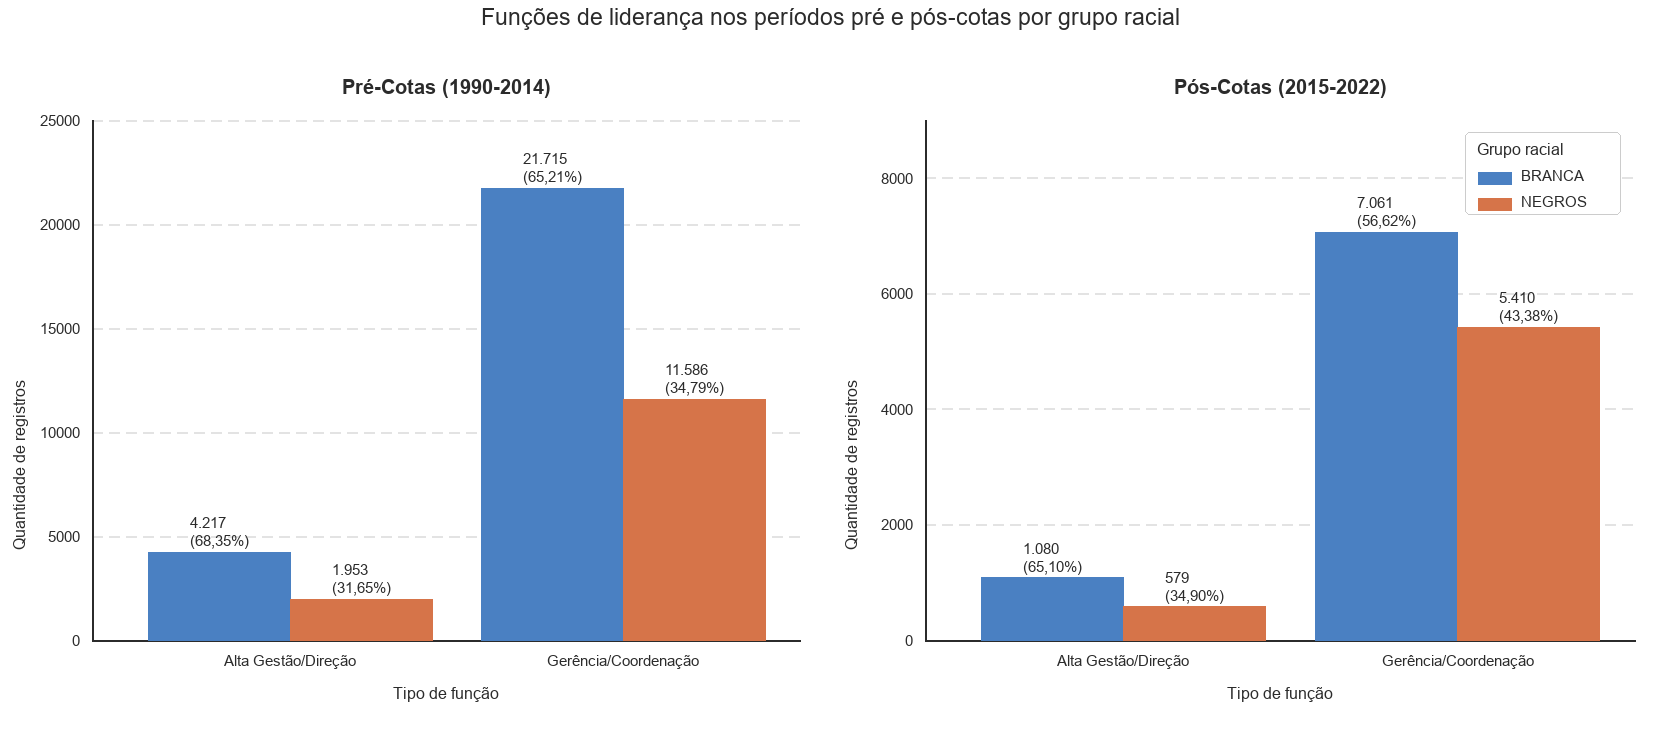

In [50]:
# Gráfico combinado: Distribuição de Cargos de Liderança por Grupo Racial - Pré-Cotas vs. Pós-Cotas
cargos_lideranca_types = ['Alta Gestão/Direção', 'Gerência/Coordenação']
racial_groups = ['BRANCA', 'NEGROS']
cargo_order = ['Alta Gestão/Direção', 'Gerência/Coordenação']
raca_order = ['BRANCA', 'NEGROS']

def _monta_df_lideranca(ano_ini, ano_fim):
    df_periodo = df_cleaned[
        (df_cleaned['ano_admissao'] >= ano_ini) &
        (df_cleaned['ano_admissao'] <= ano_fim) &
        (df_cleaned['raca_cor_agrupada'].isin(racial_groups))
    ]
    linhas = []
    for cargo_type in cargos_lideranca_types:
        contagem = df_periodo[df_periodo['cargo_hierarquico'] == cargo_type]['raca_cor_agrupada'].value_counts()
        contagem = contagem.reindex(racial_groups, fill_value=0)
        total = contagem.sum()
        percentuais = (contagem / total * 100) if total > 0 else pd.Series([0.0] * len(racial_groups), index=racial_groups)
        for raca in racial_groups:
            linhas.append({'raca_cor_agrupada': raca, 'Quantidade': contagem[raca],
                            'Tipo de Cargo': cargo_type, 'Percentual (%)': percentuais[raca]})
    return pd.DataFrame(linhas)

df_plot_pre = _monta_df_lideranca(ANO_INICIO_PRE_COTAS, ANO_FIM_PRE_COTAS)
df_plot_pos = _monta_df_lideranca(ANO_INICIO_POS_COTAS, ANO_FIM_POS_COTAS)

def _plota_painel(ax, df_plot, titulo):
    sns.barplot(x='Tipo de Cargo', y='Quantidade', hue='raca_cor_agrupada', data=df_plot,
                palette=PALETA_RACA, order=cargo_order, hue_order=raca_order, ax=ax)
    for container_idx, container in enumerate(ax.containers):
        raca_atual = raca_order[container_idx]
        for bar_idx, bar in enumerate(container.patches):
            height = bar.get_height()
            if height > 0:
                cargo_atual = cargo_order[bar_idx]
                linha = df_plot[(df_plot['Tipo de Cargo'] == cargo_atual) & (df_plot['raca_cor_agrupada'] == raca_atual)]
                if not linha.empty:
                    pct = linha['Percentual (%)'].iloc[0]
                    ax.text(bar.get_x() + bar.get_width() / 2, height + (ax.get_ylim()[1] * 0.015),
                            f'{int(height):,}\n({pct:.2f}%)', ha='center', va='bottom', fontsize=11, color='black')
    ax.set_title(titulo, fontsize=15)
    ax.set_xlabel('Tipo de Cargo', fontsize=13)
    ax.set_ylabel('Quantidade de Servidores', fontsize=13)
    ax.tick_params(axis='both', labelsize=12)
    ax.set_ylim(0, df_plot['Quantidade'].max() * 1.2)
    ax.grid(axis='y', linestyle='--', alpha=0.4)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
_plota_painel(ax1, df_plot_pre, f'Pré-Cotas ({ANO_INICIO_PRE_COTAS}-{ANO_FIM_PRE_COTAS})')
_plota_painel(ax2, df_plot_pos, f'Pós-Cotas ({ANO_INICIO_POS_COTAS}-{ANO_FIM_POS_COTAS})')
ax2.legend(title='Grupo Racial', fontsize=11, title_fontsize=12)
ax1.get_legend().remove()

fig.suptitle('Funções de Liderança nos Períodos Pré e Pós-Cotas, por Grupo Racial', fontsize=16, y=1.03)
plt.tight_layout()
plt.show()